# 07 — Economics: what a MW online is worth, what a request costs to carry, and the project NPV

Energy and capacity prices, capacity factors, credits and the value table; interconnection cost per kW and the sunk cost to the next gate; the test cohort valued; the project NPV per MW at the ATB cost of capital in a merchant and a contracted case (F26).

**Inputs → Outputs**

| Part | Was | What it does |
|---|---|---|
| A | notebook 15 | What a MW online is worth, and what a request costs to carry |

*Execution order:* Runs after notebook 04. Paths are relative to the repository root.

*Part A*

| | Path | Notes |
|---|---|---|
| in | `data/raw/value/ice_electric-2017final.xlsx … 2025final.xlsx` | EIA, ICE daily hub prices (public domain) |
| in | `data/raw/value/2024-som-pjm-sec5.pdf` | Monitoring Analytics, 2024 State of the Market, Section 5: Table 5-23 (capacity revenue by year), Table 5-13 (ELCC ratings) |
| in | `data/raw/value/irs_notice_2025-42.pdf` | IRS Notice 2025-42: begin-construction rules for wind and solar credits |
| in | `data/raw/lbnl_costs/pjm_costs_2022_clean_data.xlsx` | LBNL, PJM interconnection costs per kW by project |
| in | EIA API, `electricity/electric-power-operational-data` (annual generation by state and fuel, 2024), cached to `data/raw/value/eia_generation_2024.json` | key from `.env`, never printed |
| in | `data/raw/eia860m/eia860m_2026-07.parquet`, `data/interim/trackA.parquet`, `results/dt_tuning.json`, `results/recalibration.csv` | notebooks 01/04/06/12 |
| out | `results/value_assumptions.csv` | every assumed input with range and source |
| out | `results/energy_prices.csv`, `results/capacity_prices.csv`, `results/capacity_factors.csv`, `results/accreditation.csv` | the parsed inputs |
| out | `results/value_table.csv` | $/MW-year by region × technology × year, low / base / high |
| out | `results/cost_table.csv` | interconnection cost per kW by size band and sunk cost to the next gate |
| out | `results/expected_value_by_request.csv`, `results/expected_mw_online.csv`, `results/value_sensitivity.csv` | the test cohort valued |
| out | `figures/F13_expected_mw_and_value.*`, `figures/07_economics/*` | F13 and the notebook's figures |
| out | `results/value_checks.csv` | this notebook's checks |
| in | `data/raw/atb/ATBe_2024_v3.parquet` | NREL Annual Technology Baseline 2024 (v3): CAPEX and O&M per kW (section 8) |
| out | `results/atb_costs.csv`, `results/npv_table.csv`, `results/npv_by_request.csv`, `figures/F26_npv_per_mw.*` | NPV per MW by region × technology × COD year and case; expected NPV of every test request at entry (section 8) |

# Part A — What a MW online is worth, and what a request costs to carry (was notebook 15)

A probability of operation is not a decision. A portfolio manager weighs expected MW online, when they come, what they earn, and what it costs to keep a request alive to the next gate. This notebook builds that layer **explicitly**: every value input is either parsed from a public file on disk (EIA's wholesale prices, the PJM market monitor's capacity revenue and accreditation tables, EIA generation and capacity for capacity factors, LBNL's PJM interconnection costs) or stated as an assumption in `results/value_assumptions.csv` with a low / base / high range and a source. The value is an *index* for comparing requests and books, not a valuation: no discounting, no financing, no tax detail beyond a credit on/off. It is then applied to the test cohort to give each request an expected value and the cohort an expected MW-online path, with a sensitivity grid.

## Setup

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, drift, eia_api, paths, plots, value, variants

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "07_economics"
TRACK_A = config.TRACK_A_REGIONS
START = time.time()
YEARS = list(range(2017, 2031))  # the value table's years: test entry years through a ten-year window
WINDOW = 10  # years after entry over which a request is valued
TECHS = list(config.TECH_COLORS)  # Solar, Solar+Battery, Wind, Offshore Wind, Battery, Gas, Other
CASES = ["low", "base", "high"]


def save(fig, name, caption):
    """Save a figure of this notebook under figures/07_economics/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Energy prices: EIA's ICE hub files

Volume-weighted annual on-peak prices per hub (`src/value.ice_hub_prices`). PJM is read at PJM West, CAISO at SP15; ERCOT North is traded in these files only through 2019, so ERCOT's later years are extended by PJM West's year-to-year index from the 2017–2019 ratio — an assumption, recorded as such. Years after 2025 hold the 2025 value.

In [2]:
hubs = value.ice_hub_prices()
energy = pd.DataFrame(index=YEARS)
for region, hub in value.HUB_BY_REGION.items():
    energy[region] = hubs.loc[hub].reindex(YEARS)
ratio = (energy.loc[2017:2019, "ERCOT"] / energy.loc[2017:2019, "PJM"]).mean()
extended = energy["ERCOT"].isna() & energy["PJM"].notna()
energy.loc[extended, "ERCOT"] = energy.loc[extended, "PJM"] * ratio
energy = energy.ffill()  # years beyond the files hold the last observed value
energy.index.name = "year"
energy.round(2).to_csv(paths.RESULTS / "energy_prices.csv")
assumptions = [{"input": "ERCOT energy price 2020 onward", "value": f"PJM West × {ratio:.2f}", "low": "× 0.7", "high": "× 1.3",
                "source": "ERCOT North traded in EIA's ICE files only 2017–2019; ratio of the 2017–2019 means", "verified": "assumption"},
               {"input": "prices after 2025", "value": "held at 2025", "low": "", "high": "", "source": "no forward curve used", "verified": "assumption"}]
print(f"ERCOT/PJM on-peak price ratio 2017–2019: {ratio:.2f}; extended years: {int(extended.sum())}")
energy.round(1).T

ERCOT/PJM on-peak price ratio 2017–2019: 0.77; extended years: 6


year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
PJM,36.8,45.2,35.4,25.6,48.5,90.5,42.1,48.4,68.2,68.2,68.2,68.2,68.2,68.2
CAISO,44.3,62.3,42.6,52.0,65.1,100.1,64.8,37.2,30.8,30.8,30.8,30.8,30.8,30.8
ERCOT,27.6,28.4,32.9,19.7,37.3,69.6,32.4,37.2,52.4,52.4,52.4,52.4,52.4,52.4


**Reading this.** The on-peak hub price is the first and largest term of the value. PJM West ran from $36.8/MWh in 2017 to $90.5 in 2022 and $68.2 in 2025; SP15 from $44.3 to $100.1 in 2022 and down to $30.8 in 2025, as California's midday prices collapsed under solar; ERCOT North traded at $27.6–32.9 in 2017–2019, 0.77 of PJM West, and that ratio carries ERCOT's later years. Two things follow for the value index: a request that reaches operation in 2022 is worth far more per MW-year than one that arrives in 2020, and the ERCOT line after 2019 is an assumption, not a price.

## 2. Capacity prices and accreditation

PJM: the market monitor's cleared-UCAP-weighted RPM price by calendar year (Table 5-23, $/MW-day → $/kW-year), and the final 2025/2026 marginal ELCC class ratings (Table 5-13), both parsed from the PDF. CAISO has a bilateral resource-adequacy market whose prices are published by the CPUC; no file could be fetched from here, so the CAISO price is an assumption with a wide range. ERCOT is an energy-only market: capacity price zero, with its scarcity value in the energy price. Accreditation by technology group maps PJM's classes onto the project's seven groups and is used for CAISO as a proxy.

In [3]:
rpm = value.pjm_capacity_revenue()
elcc = value.pjm_elcc_ratings()
capacity_price = pd.DataFrame(index=YEARS)
capacity_price["PJM"] = (rpm.reindex(YEARS) * 365 / 1000).ffill()  # $/MW-day → $/kW-year; after 2026 hold
CAISO_RA_KW_MONTH = {"low": 4.0, "base": 8.0, "high": 12.0}  # $/kW-month, assumption (CPUC Resource Adequacy reports; verify)
capacity_price["CAISO"] = CAISO_RA_KW_MONTH["base"] * 12
capacity_price["ERCOT"] = 0.0
capacity_price.index.name = "year"
capacity_price.round(2).to_csv(paths.RESULTS / "capacity_prices.csv")
accreditation = pd.Series({
    "Solar": float((elcc["Solar Fixed"] + elcc["Solar Tracking"]) / 2), "Solar+Battery": float((elcc["Solar Tracking"] + elcc["4-hr Storage"]) / 2),
    "Wind": float(elcc["Onshore Wind"]), "Offshore Wind": float(elcc["Offshore Wind"]), "Battery": float(elcc["4-hr Storage"]),
    "Gas": float((elcc["Gas Combined Cycle"] + elcc["Gas Combustion Turbine"]) / 2), "Other": 0.5}, name="accreditation")
accreditation.to_csv(paths.RESULTS / "accreditation.csv")
assumptions += [
    {"input": "CAISO capacity price", "value": f"${CAISO_RA_KW_MONTH['base']}/kW-month", "low": f"${CAISO_RA_KW_MONTH['low']}", "high": f"${CAISO_RA_KW_MONTH['high']}",
     "source": "CPUC Resource Adequacy reports (not fetched from this machine)", "verified": "assumption — verify"},
    {"input": "ERCOT capacity price", "value": "0", "low": "0", "high": "0", "source": "energy-only market", "verified": "by design"},
    {"input": "PJM capacity price after 2026", "value": "held at 2026 (partial year)", "low": "", "high": "", "source": "Monitoring Analytics 2024 SOM Table 5-23", "verified": "parsed"},
    {"input": "accreditation by technology group", "value": "PJM 2025/26 ELCC class averages", "low": "× 0.7", "high": "× 1.3",
     "source": "Monitoring Analytics 2024 SOM Table 5-13 (Jan 23, 2025 column); applied to CAISO as a proxy", "verified": "parsed; mapping is an assumption"},
]
print(f"PJM capacity revenue, $/kW-year: 2018 {capacity_price.loc[2018, 'PJM']:.1f}, 2024 {capacity_price.loc[2024, 'PJM']:.1f}, "
      f"2025 {capacity_price.loc[2025, 'PJM']:.1f}, 2026 {capacity_price.loc[2026, 'PJM']:.1f}")
display(accreditation.round(2).to_frame().T)
capacity_price.round(1).T

PJM capacity revenue, $/kW-year: 2018 58.1, 2024 16.1, 2025 70.3, 2026 108.2


,Solar,Solar+Battery,Wind,Offshore Wind,Battery,Gas,Other
accreditation,0.12,0.34,0.38,0.62,0.55,0.7,0.5


year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
PJM,48.6,58.1,49.5,40.4,48.3,37.7,19.9,16.1,70.3,108.2,108.2,108.2,108.2,108.2
CAISO,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0
ERCOT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Reading this.** PJM's capacity revenue is the most volatile input: $58/kW-year in 2018, $16 in 2024, $70 in 2025 and $108 in 2026 (a partial year), parsed from the market monitor's table. Accreditation decides how much of a plant's nameplate earns it: 12% for solar, 38% for onshore wind, 55% for four-hour storage, 70% for gas, which is why a MW of gas carries several times the capacity value of a MW of solar in PJM. CAISO's $96/kW-year is an assumption with a range of $48–144 and is flagged for verification; ERCOT's zero is by design. These numbers are an index of relative worth, not a forecast of any plant's revenue.

## 3. Capacity factors: EIA generation over EIA-860M nameplate

Annual 2024 net generation by state and fuel from the EIA API (cached as JSON, key never printed) over the operating nameplate by state and technology group from the EIA-860M pull of notebook 01 (July 2026 inventory — a vintage mismatch of up to two years, accepted and stated). The capacity factor for a request is the one of its state and technology group; a state without that technology takes the national value. Storage has no meaningful capacity factor and earns capacity value only.

In [4]:
cache = paths.DATA_RAW / "value" / "eia_generation_2024.json"
FUEL_TO_TECH = {"SUN": "Solar", "WND": "Wind", "NG": "Gas", "NUC": "Nuclear", "COW": "Coal", "HYC": "Hydro", "GEO": "Geothermal"}
if cache.exists():
    gen_rows = json.loads(cache.read_text(encoding="utf-8"))
else:
    key = eia_api.load_api_key()
    url = f"{config.EIA_API_BASE}/electricity/electric-power-operational-data/data/"
    gen_rows, offset = [], 0
    while True:
        page = eia_api._get(url, {"frequency": "annual", "data[]": ["generation"], "facets[sectorid][]": "99",
                                  "facets[fueltypeid][]": list(FUEL_TO_TECH), "start": "2024", "end": "2024",
                                  "length": config.EIA_PAGE_LENGTH, "offset": offset}, key)
        gen_rows += page["response"]["data"]
        offset += config.EIA_PAGE_LENGTH
        if offset >= int(page["response"]["total"]):
            break
    text = json.dumps(gen_rows)
    assert key not in text
    cache.write_text(text, encoding="utf-8")
gen = pd.DataFrame(gen_rows)
gen = gen[(gen["location"].str.len() == 2) & (gen["location"] != "US")].copy()  # states only: the route also carries census regions and "US"
gen["mwh"] = pd.to_numeric(gen["generation"], errors="coerce") * 1000  # thousand MWh → MWh
gen["tech"] = gen["fueltypeid"].map(FUEL_TO_TECH)
gen = gen.groupby(["location", "tech"], as_index=False)["mwh"].sum().rename(columns={"location": "state"})

eia = pd.read_parquet(sorted((paths.RAW_EIA860M).glob("eia860m_*.parquet"))[-1])
eia = eia[eia["status"] == "OP"].copy()
eia["mw"] = pd.to_numeric(eia["nameplate-capacity-mw"], errors="coerce")
eia["tech"] = eia["technology"].map(lambda t: config.EIA_TECHNOLOGY_MAP.get(t, ("Other", ""))[0])
cap = eia.groupby(["stateid", "tech"], as_index=False)["mw"].sum().rename(columns={"stateid": "state"})
cf = value.capacity_factors(gen, cap)
cf = cf[cf["mw"] >= 50]  # a state needs 50 MW of a technology for its factor to mean anything
national = (gen.groupby("tech")["mwh"].sum() / (cap.groupby("tech")["mw"].sum() * value.HOURS_PER_YEAR)).clip(0, 1)
cf.to_csv(paths.RESULTS / "capacity_factors.csv", index=False)
OFFSHORE_CF, OTHER_CF = 0.40, 0.30  # no operating fleet to measure (offshore) or too mixed (other); assumptions
assumptions += [
    {"input": "capacity factors", "value": "2024 generation / July-2026 nameplate, by state × technology", "low": "× 0.85", "high": "× 1.15",
     "source": "EIA API electric-power-operational-data; EIA-860M (notebook 01)", "verified": "computed; vintage mismatch stated"},
    {"input": "offshore wind capacity factor", "value": OFFSHORE_CF, "low": 0.35, "high": 0.45, "source": "no operating U.S. fleet in 2024 data", "verified": "assumption"},
    {"input": "'Other' technology capacity factor", "value": OTHER_CF, "low": 0.2, "high": 0.5, "source": "mixed group", "verified": "assumption"},
]
print(f"state × technology factors: {len(cf)}; national: " + ", ".join(f"{t} {v:.2f}" for t, v in national.round(2).items()))
cf[cf["state"].isin(["TX", "CA", "PA"])].pivot(index="state", columns="tech", values="capacity_factor").round(2)

state × technology factors: 245; national: Battery nan, Coal 0.42, Gas 0.38, Geothermal 0.46, Hydro 0.29, Nuclear 0.88, Offshore Wind nan, Other nan, Solar 0.15, Wind 0.31


tech,Coal,Gas,Geothermal,Hydro,Nuclear,Solar,Wind
state,,,,,,,
CA,0.51,0.25,0.44,0.25,0.90,0.22,0.28
PA,0.29,0.56,NaN,0.13,0.90,0.10,0.22
TX,0.48,0.41,NaN,0.13,0.86,0.14,0.32


**Reading this.** Capacity factors from the data: in Texas, 0.14 for solar, 0.32 for wind, 0.41 for gas; in California 0.22, 0.28 and 0.25; in Pennsylvania 0.10, 0.22 and 0.56. Nationally 0.15 for solar, 0.31 for wind and 0.38 for gas (2024 generation over the July-2026 fleet, which understates factors where capacity grew fast in 2025–2026 — solar most of all). 245 state × technology factors are used; a request whose state lacks its technology takes the national value. Storage earns no energy value here, which undervalues it where arbitrage pays.

## 4. Credits, capture and the value table

Two more stated inputs: the *capture* of the on-peak hub price by technology (solar and wind sell into lower-priced hours than the on-peak average; gas captures it; storage earns capacity value only here), and a production credit for wind and solar that reach operation by the end of 2027 — the deadline IRS Notice 2025-42 sets for projects that have not begun construction by July 4, 2026 — at a stated $/MWh. The value table then follows `src/value.value_per_mw_year` for every region × technology × year under low, base and high multipliers.

In [5]:
CAPTURE = {"Solar": 0.8, "Solar+Battery": 0.85, "Wind": 0.8, "Offshore Wind": 0.85, "Battery": 0.0, "Gas": 1.0, "Other": 0.9}
CREDIT_USD_MWH = 27.5  # production credit for wind and solar, $/MWh; statutory base rate as inflation-adjusted (verify)
CREDIT_LAST_COD_YEAR = 2027  # IRS Notice 2025-42: placed in service by end-2027 unless construction began by 2026-07-04
MULTIPLIER = {"low": {"energy": 0.7, "capacity": 0.5, "credit": 0.0}, "base": {"energy": 1.0, "capacity": 1.0, "credit": 1.0},
              "high": {"energy": 1.3, "capacity": 1.5, "credit": 1.0}}
assumptions += [
    {"input": "capture of the on-peak price", "value": str(CAPTURE), "low": "energy × 0.7", "high": "energy × 1.3", "source": "assumption", "verified": "assumption"},
    {"input": "production credit, wind and solar", "value": f"${CREDIT_USD_MWH}/MWh if operating by {CREDIT_LAST_COD_YEAR}", "low": "0", "high": f"${CREDIT_USD_MWH}",
     "source": "IRC §45 base rate inflation-adjusted (verify the year's rate); deadline from IRS Notice 2025-42 (data/raw/value/irs_notice_2025-42.pdf)", "verified": "deadline from the notice; rate to verify"},
    {"input": "case multipliers", "value": str(MULTIPLIER), "low": "", "high": "", "source": "assumption", "verified": "assumption"},
]
pd.DataFrame(assumptions).to_csv(paths.RESULTS / "value_assumptions.csv", index=False)

cf_lookup = {(r.state, r.tech): r.capacity_factor for r in cf.itertuples()}


def tech_cf(state, tech):
    base = {"Solar": "Solar", "Solar+Battery": "Solar", "Wind": "Wind", "Gas": "Gas"}.get(tech)
    if tech == "Offshore Wind":
        return OFFSHORE_CF
    if tech == "Battery":
        return 0.0
    if base is None:
        return OTHER_CF
    return cf_lookup.get((state, base), float(national.get(base, OTHER_CF)))


def inputs_for(state, cod_year):
    """The value inputs of one request: its state's capacity factors and the credit if it operates in time."""
    return {"energy_price": {r: energy[r].to_dict() for r in TRACK_A},
            "capacity_factor": {t: tech_cf(state, t) for t in TECHS},
            "capture": CAPTURE,
            "capacity_price": {r: capacity_price[r].to_dict() for r in TRACK_A},
            "accreditation": accreditation.to_dict(),
            "credit": {t: (CREDIT_USD_MWH if t in ("Solar", "Solar+Battery", "Wind", "Offshore Wind") and cod_year <= CREDIT_LAST_COD_YEAR else 0.0) for t in TECHS},
            "multiplier": MULTIPLIER}


rows = []
for region in TRACK_A:
    state = {"PJM": "PA", "CAISO": "CA", "ERCOT": "TX"}[region]  # the table is shown for each region's largest state
    for tech in TECHS:
        for year in YEARS:
            rec = {"region": region, "state": state, "tech": tech, "year": year}
            for case in CASES:
                rec[case] = value.value_per_mw_year(region, tech, year, inputs_for(state, year), case)
            rows.append(rec)
value_table = pd.DataFrame(rows)
value_table.round(0).to_csv(paths.RESULTS / "value_table.csv", index=False)
show = value_table[value_table["year"] == 2024].pivot(index="tech", columns="region", values="base").round(-3)
show

region,CAISO,ERCOT,PJM
tech,,,
Battery,53000.0,0.0,9000.0
Gas,149000.0,133000.0,249000.0
Offshore Wind,267000.0,207000.0,250000.0
Other,136000.0,88000.0,123000.0
Solar,120000.0,70000.0,62000.0
Solar+Battery,145000.0,72000.0,68000.0
Wind,175000.0,162000.0,135000.0


**Reading this.** In 2024 and the base case, a MW online is worth about $249,000 a year for gas in PJM, $135,000 for wind and $62,000 for solar; in CAISO solar rises to $120,000 because the capacity price is assumed and the credit applies; in ERCOT, with no capacity price, solar is worth $70,000 and a battery nothing (an admitted gap). The order across technologies is set by capacity factor and accreditation; the order across years by the hub price and PJM's capacity revenue. Every term, its range and its source are in `results/value_assumptions.csv`; the low case halves the capacity value, cuts energy by 30% and removes the credit, the high case does the reverse.

## 5. Costs: interconnection cost per kW and the sunk cost to the next gate

LBNL's PJM data give 1,127 project-level interconnection cost estimates in $2022/kW. The median by size band is the cost exposure of a request of that size; it is applied to CAISO and ERCOT as a proxy (their costs are not in the file) with a wide range. The sunk cost to the next decision gate is a share of that exposure (deposits, studies) plus a fixed study cost — both assumptions with ranges.

In [6]:
costs = value.pjm_cost_table()
by_size = costs.groupby("size_regime", observed=True)["total_cost_per_kw"].agg(["median", "size"]).reindex(config.SIZE_LABELS)
by_size.columns = ["cost_per_kw_median", "n_projects"]
by_size["cost_per_kw_median"] = by_size["cost_per_kw_median"].fillna(costs["total_cost_per_kw"].median())
DEPOSIT_SHARE = {"low": 0.05, "base": 0.10, "high": 0.20}  # share of the interconnection cost committed before the next gate
STUDY_COST = {"low": 50_000, "base": 150_000, "high": 500_000}  # $ per request to the next gate
cost_table = by_size.copy()
for case in CASES:
    cost_table[f"sunk_per_mw_{case}"] = cost_table["cost_per_kw_median"] * 1000 * DEPOSIT_SHARE[case]
cost_table.to_csv(paths.RESULTS / "cost_table.csv")
assumptions += [
    {"input": "interconnection cost per kW outside PJM", "value": "PJM median by size band", "low": "× 0.5", "high": "× 2", "source": "LBNL PJM cost data (no CAISO/ERCOT file)", "verified": "proxy"},
    {"input": "deposit share of interconnection cost to the next gate", "value": DEPOSIT_SHARE["base"], "low": DEPOSIT_SHARE["low"], "high": DEPOSIT_SHARE["high"], "source": "assumption", "verified": "assumption"},
    {"input": "study cost to the next gate, $ per request", "value": STUDY_COST["base"], "low": STUDY_COST["low"], "high": STUDY_COST["high"], "source": "assumption", "verified": "assumption"},
]
pd.DataFrame(assumptions).to_csv(paths.RESULTS / "value_assumptions.csv", index=False)
print(f"{len(costs):,} PJM cost estimates; overall median ${costs['total_cost_per_kw'].median():.0f}/kW, "
      f"network upgrades median ${costs['network_cost_per_kw'].median():.0f}/kW")
cost_table.round(0)

1,127 PJM cost estimates; overall median $61/kW, network upgrades median $39/kW


,cost_per_kw_median,n_projects,sunk_per_mw_low,sunk_per_mw_base,sunk_per_mw_high
size_regime,,,,,
<5,30.0,80,1510.0,3021.0,6041.0
5–<20,38.0,164,1906.0,3813.0,7626.0
20–<100,82.0,517,4084.0,8169.0,16338.0
100–<200,76.0,189,3818.0,7636.0,15271.0
200–<500,44.0,110,2194.0,4387.0,8774.0
≥500,8.0,67,421.0,841.0,1683.0


**Reading this.** PJM's interconnection cost estimates have a median of $61/kW and a long tail (the 75th percentile is $157, the maximum $10,189). By size band the median rises from $30/kW under 5 MW to $82 at 20–100 MW and $76 at 100–200 MW, then falls to $44 at 200–500 MW and $8 above 500 MW — the largest requests in this file are mostly gas and nuclear uprates at existing points of interconnection. The sunk cost to the next gate is a tenth of that exposure per MW (base), $3,000–8,000 per MW, plus $150,000 of studies; it is small next to the expected value of most requests and matters only for the smallest, where it turns a few expected values negative.

## 6. The test cohort valued: expected MW online and expected value per request

The v2 model (notebook 11's choice) is refitted on entrants to 2016 and its yearly P(operation by year 1 … 10) read for every test request, raw and with the rolling level repair of notebook 12 (the 5-year intercept of the request's region and entry year, applied to the whole curve — a simplification stated here). Expected MW online by year is the sum over requests of MW × P(operates in that year); expected value follows `src/value.expected_value` with the request's own state capacity factors, the value table's years from its entry year, and the sunk cost of its size band.

In [7]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
chosen = json.loads((paths.RESULTS / "variant_chosen.json").read_text(encoding="utf-8"))["chosen"]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
fit = variants.fit_candidate(variants.CANDIDATES[chosen], final, clean, tuning)
curve = discrete_time.predict_both(fit, test, horizons=list(range(1, WINDOW + 1)))[variants.CANDIDATES[chosen]["model"]]
P_raw = curve[list(range(1, WINDOW + 1))].to_numpy()
recal = pd.read_csv(paths.RESULTS / "recalibration.csv")
shift = recal[recal["horizon"] == 5].set_index(["scored_year", "region"])["intercept"]
a = np.array([shift.get((int(y), r), 0.0) for y, r in zip(test["q_year"], test["region"].astype(str))])
P_recal = drift.apply_intercept(P_raw, a[:, None])

records, mw_online = [], {case: {v: np.zeros(WINDOW) for v in ["raw", "recalibrated"]} for case in CASES}
for i, (idx, r) in enumerate(test.iterrows()):
    years_ahead = [int(r["q_year"]) + j for j in range(1, WINDOW + 1)]
    sunk = {case: cost_table.loc[str(r["size_regime"]), f"sunk_per_mw_{case}"] * r["mw"] + STUDY_COST[case] for case in CASES}
    rec = {"project_key": str(r["project_key"]), "region": r["region"], "tech": r["tech"], "state": r["state"], "mw": r["mw"],
           "q_year": int(r["q_year"]), "size_regime": str(r["size_regime"]), "event": int(r["event"]), "duration_years": r["duration_years"],
           "p5_raw": P_raw[i, 4], "p5_recalibrated": P_recal[i, 4]}
    for version, P in [("raw", P_raw), ("recalibrated", P_recal)]:
        increments = np.diff(np.concatenate([[0.0], P[i]]))
        rec[f"expected_mw_online_{version}"] = float(P[i, -1] * r["mw"])
        for case in CASES:
            vals = [value.value_per_mw_year(r["region"], r["tech"], y, inputs_for(r["state"], y), case) for y in years_ahead]
            rec[f"value_{version}_{case}"] = value.expected_value(P[i], r["mw"], vals, sunk[case])
            mw_online[case][version] += increments * r["mw"]
    records.append(rec)
valued = pd.DataFrame(records)
valued.to_csv(paths.RESULTS / "expected_value_by_request.csv", index=False)
path = pd.DataFrame({"years_after_entry": range(1, WINDOW + 1),
                     **{f"expected_mw_{v}": np.cumsum(mw_online["base"][v]) for v in ["raw", "recalibrated"]}})
realised = np.array([float(test.loc[(test["event"] == 1) & (test["duration_years"] <= j), "mw"].sum()) for j in range(1, WINDOW + 1)])
observable = np.array([(((pd.Timestamp(config.CENSOR_DATE) - test["q_date"]).dt.days / config.DAYS_PER_YEAR) >= j).mean() for j in range(1, WINDOW + 1)])
path["realised_mw_by_end_2024"], path["share_of_cohort_observable"] = realised, observable
path.to_csv(paths.RESULTS / "expected_mw_online.csv", index=False)
print(f"{len(valued):,} requests valued ({(time.time() - START) / 60:.1f} min); cohort MW {test['mw'].sum():,.0f}; "
      f"expected MW online within 5 years: raw {np.cumsum(mw_online['base']['raw'])[4]:,.0f}, recalibrated "
      f"{np.cumsum(mw_online['base']['recalibrated'])[4]:,.0f}; realised by end-2024 within 5 years: {realised[4]:,.0f}")
summary = valued[["mw", "p5_raw", "p5_recalibrated"]].describe().round(3)
summary_value = (valued[["value_raw_base", "value_recalibrated_base", "value_recalibrated_low", "value_recalibrated_high"]] / 1e6).describe().round(2)
display(summary)
summary_value

2,268 requests valued (0.2 min); cohort MW 348,901; expected MW online within 5 years: raw 29,245, recalibrated 25,221; realised by end-2024 within 5 years: 18,772


,mw,p5_raw,p5_recalibrated
count,2268.000,2268.000,2268.000
mean,153.837,0.136,0.112
std,257.664,0.101,0.100
min,0.200,0.004,0.005
25%,20.000,0.071,0.049
50%,80.000,0.112,0.080
75%,200.000,0.171,0.143
max,5120.000,0.722,0.731


,value_raw_base,value_recalibrated_base,value_recalibrated_low,value_recalibrated_high
count,2268.00,2268.00,2268.00,2268.00
mean,19.10,16.15,8.52,19.52
std,39.23,31.28,18.65,40.15
min,-1.32,-1.32,-0.63,-2.84
25%,1.63,1.06,0.52,0.93
50%,7.91,5.46,2.68,6.10
75%,20.84,17.82,8.69,20.97
max,584.76,436.81,290.90,582.07


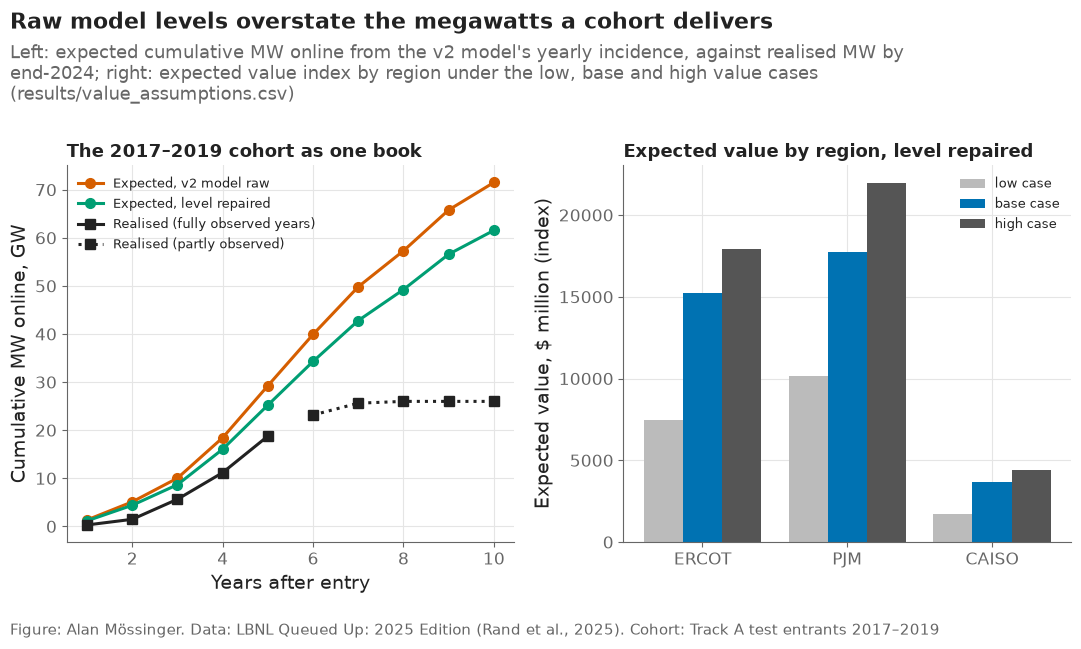

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
ax = axes[0]
ax.plot(path["years_after_entry"], path["expected_mw_raw"] / 1e3, marker="o", color="#D55E00", label="Expected, v2 model raw")
ax.plot(path["years_after_entry"], path["expected_mw_recalibrated"] / 1e3, marker="o", color="#009E73", label="Expected, level repaired")
obs = path[path["share_of_cohort_observable"] >= 0.99]
ax.plot(obs["years_after_entry"], obs["realised_mw_by_end_2024"] / 1e3, marker="s", color=plots.INK, label="Realised (fully observed years)")
part = path[path["share_of_cohort_observable"] < 0.99]
ax.plot(part["years_after_entry"], part["realised_mw_by_end_2024"] / 1e3, marker="s", linestyle=":", color=plots.INK, label="Realised (partly observed)")
ax.set_xlabel("Years after entry")
ax.set_ylabel("Cumulative MW online, GW")
ax.set_title("The 2017–2019 cohort as one book", fontsize=13)
ax.legend(fontsize=9, loc="upper left")
ax = axes[1]
by_region = valued.groupby("region")[[f"value_recalibrated_{c}" for c in CASES]].sum() / 1e6
x = np.arange(len(TRACK_A))
for c_i, case in enumerate(CASES):
    ax.bar(x + (c_i - 1) * 0.27, by_region.loc[TRACK_A, f"value_recalibrated_{case}"], width=0.27,
           color={"low": "#BBBBBB", "base": "#0072B2", "high": "#555555"}[case], label=f"{case} case")
ax.set_xticks(x, TRACK_A)
ax.set_ylabel("Expected value, $ million (index)")
ax.set_title("Expected value by region, level repaired", fontsize=13)
ax.legend(fontsize=9)
r5 = realised[4] / 1e3
plots.finish(fig,
             f"The 2017–2019 cohort was expected to bring {path['expected_mw_raw'].iloc[4] / 1e3:,.1f} GW online within five years "
             f"(raw) or {path['expected_mw_recalibrated'].iloc[4] / 1e3:,.1f} GW (level repaired); {r5:,.1f} GW did",
             "Left: expected cumulative MW online from the v2 model's yearly incidence, against realised MW by end-2024; "
             "right: expected value index by region under the low, base and high value cases (results/value_assumptions.csv)",
             "Track A test entrants 2017–2019")
plots.save_fig(fig, "F13_expected_mw_and_value",
               "Expected cumulative MW online of the 2017–2019 cohort against realised MW, and the expected value index by region under three value cases.",
               NOTEBOOK)
plt.show()

**Reading this.** The 2017–2019 cohort is 348,901 MW of requests. The v2 model expected 29,245 MW of it to be online within five years; the level repair brings that to 25,221 MW; 18,772 MW actually were by end-2024. The level error of notebook 12, in megawatts, is 56% (raw) or 34% (repaired) over the realised figure — a portfolio built on the raw curve would have been sized for a third more capacity than arrived. Per request, the base-case expected value has a median of $5.5 million and a mean of $16 million (repaired), with a few negative values where the sunk cost exceeds a near-zero probability times a small plant. The right panel puts PJM and ERCOT at $15–18 billion of expected value each and CAISO at $3.6 billion: CAISO's requests are fewer and less likely to be built, and its assumed capacity price does not make up the difference.

## 7. Sensitivity: does the value case change the ranking?

The value index moves a lot between cases; what matters for a book is whether the *order* of requests moves. Spearman correlation of expected value across cases and versions, and the share of the top decile that stays in the top decile.

In [9]:
cols = {f"{v} / {c}": f"value_{v}_{c}" for v in ["raw", "recalibrated"] for c in CASES}
corr = valued[list(cols.values())].corr(method="spearman").round(3)
corr.index = corr.columns = list(cols)
top = {}
base_top = set(valued.nlargest(len(valued) // 10, "value_recalibrated_base")["project_key"])
for label, col in cols.items():
    top[label] = len(base_top & set(valued.nlargest(len(valued) // 10, col)["project_key"])) / len(base_top)
sens = corr.copy()
sens["top-decile overlap with recalibrated/base"] = pd.Series(top)
sens.to_csv(paths.RESULTS / "value_sensitivity.csv")
sens

,raw / low,raw / base,raw / high,recalibrated / low,recalibrated / base,recalibrated / high,top-decile overlap with recalibrated/base
raw / low,1.000,0.996,0.998,0.981,0.973,0.973,0.774336
raw / base,0.996,1.000,0.999,0.983,0.981,0.979,0.840708
raw / high,0.998,0.999,1.000,0.982,0.978,0.978,0.823009
recalibrated / low,0.981,0.983,0.982,1.000,0.997,0.998,0.902655
recalibrated / base,0.973,0.981,0.978,0.997,1.000,0.999,1.000000
recalibrated / high,0.973,0.979,0.978,0.998,0.999,1.000,0.973451


**Reading this.** The value case barely moves the order of requests: Spearman correlations of 0.973–0.999 across the six versions, and 90–97% of the recalibrated base case's top decile stays in the top decile under the low and high cases. The level repair moves the order more than the value assumptions do (0.97–0.98 between raw and repaired; 78–84% top-decile overlap), because it shifts regions by different amounts. For the portfolio notebook this means the choice of book is driven by the probabilities, MW and technology mix, and the value assumptions change what the book is worth, not which book it is.

## 8. What a project is worth: NPV per MW, merchant and contracted (F26)

Sections 4–6 priced a MW *online* and summed it over a window: an index of revenue, with no capital cost, so a large request always looked worth more than a small one and a battery in ERCOT looked worth nothing. An energy company decides on net present value: what the plant earns over its life, less what it costs to build and run, discounted at its cost of capital. This section builds the simplest project DCF the public files allow, in the two ways a developer looks at a plant.

`NPV = −CAPEX × (1 − ITC) + Σ_t (revenue_t − fixed O&M − variable cost_t) / (1 + r)^t` over a 20-year life from the commercial operation date. Overnight capital and O&M per kW come from the NREL Annual Technology Baseline 2024 (Moderate scenario, Market case, one representative class per technology; `src/value.atb_costs`), gas fuel from heat rate × a gas-price assumption, and the credits as a developer would elect them: the 30% investment credit for solar, hybrids, storage and offshore wind, the production credit for wind for its first ten years, neither after the 2027 deadline of section 4. Revenue uses the formula of section 4 (energy at the on-peak hub price and the technology's capture, capacity revenue, the credit) with a **new plant's capacity factor** from the ATB class, because the fleet figure of section 3 divides 2024 generation by 2026 nameplate and understates what a plant built today produces (PJM solar 10% against 27%). The discount rate is the ATB's own real cost of capital for the technology's Market financing case (4.2% solar and hybrids, 4.9% wind, 5.2% offshore, 5.4% gas; `src/value.atb_wacc`), which is how practice does it: cash flows at the project's cost of capital, the chance of never reaching operation carried as a probability by the gates of notebook 16, not as a higher rate; 8% is kept as a stress case.

The **merchant** case sells energy at the hub price. The **contracted** case is how a developer underwrites a plant: a power purchase agreement at a market index price for the first 15 years (solar, wind, hybrids and offshore wind; the index values are assumptions with a range, listed in `results/value_assumptions.csv`), capacity revenue and the credit as before, merchant after the contract ends. Gas, storage and the "Other" group have no public contract index and stay merchant in both cases. No financing structure, no tax depreciation, no degradation, no terminal value, no energy revenue for storage: enough to rank technologies and regions and to put a sign on a request, which is what the gates need; not enough to price one. Costs are in 2022 dollars against a value table in the dollars of each year; the gap is a few percent and is stated. The break-even flat price (the $/MWh at which the merchant NPV is zero) is reported next to the price the table captures, because that is the number a company compares with the contract it can sign.

In [10]:
import functools

value.fetch_atb()  # downloads data/raw/atb/ATBe_2024_v3.parquet if missing and checks its hash (source S12)
atb = value.atb_costs()
atb_cf = value.atb_capacity_factors()
WACC = value.atb_wacc()
NEW_BUILD_CF = {t: atb_cf.get(t, np.nan) for t in TECHS}
NEW_BUILD_CF.update({"Battery": 0.0, "Other": OTHER_CF})  # storage: capacity revenue only; Other: the section-3 assumption
NEW_BUILD_CF["Gas"] = float(national.get("Gas", OTHER_CF))  # a new combined cycle is dispatched like the fleet; ATB gives no CF for gas
GAS_PRICE = {"low": 5.0, "base": 3.5, "high": 2.5}  # $/MMBtu; the low value case takes the high fuel price
ITC_SHARE = 0.30  # IRC §48E base rate with prevailing wage, for plants in service by CREDIT_LAST_COD_YEAR
ITC_TECHS = ("Solar", "Solar+Battery", "Battery", "Offshore Wind")  # elect the investment credit; wind elects the production credit
PTC_YEARS = 10  # the production credit is paid for the first ten years of operation (IRC §45Y)
STRESS_RATE = 0.08  # a stress case on the cost of capital, next to the ATB Market-case WACC per technology
LIFE = 20
PPA_YEARS = 15  # contract term of the contracted case
PPA_PRICE = {"Solar": 57.0, "Wind": 62.0, "Solar+Battery": 70.0, "Offshore Wind": 110.0}  # $/MWh, base; low = −10, high = +10
PPA_SPREAD = 10.0
assumptions += [
    {"input": "capital and O&M cost per kW", "value": "NREL ATB 2024 v3, Moderate / Market / 20-year CRP, one class per technology (src/value.ATB_MAP); 2022 dollars",
     "low": "", "high": "", "source": "data/raw/atb/ATBe_2024_v3.parquet (OEDI data lake, downloaded 2026-10-12)", "verified": "parsed"},
    {"input": "capacity factor of a new plant (NPV only)", "value": str({k: round(v, 3) for k, v in NEW_BUILD_CF.items()}), "low": "", "high": "",
     "source": "ATB 2024 class CF for solar, hybrid, wind, offshore; EIA fleet CF for gas; section 3 assumption for Other", "verified": "parsed; choice stated"},
    {"input": "real cost of capital by technology (NPV discount rate)", "value": str({k: round(v, 4) for k, v in WACC.items()}), "low": f"{STRESS_RATE:.0%} stress", "high": "",
     "source": "ATB 2024 Market financing case, WACC Real (src/value.atb_wacc); storage takes the solar rate, Other the median", "verified": "parsed; mapping stated"},
    {"input": "natural gas price, $/MMBtu", "value": GAS_PRICE["base"], "low": GAS_PRICE["low"], "high": GAS_PRICE["high"],
     "source": "assumption; Henry Hub traded between about $2 and $6 over 2017–2024", "verified": "assumption"},
    {"input": "investment tax credit", "value": f"{ITC_SHARE:.0%} of CAPEX for {', '.join(ITC_TECHS)} in service by {CREDIT_LAST_COD_YEAR}; wind takes the production credit instead",
     "low": "0 after the deadline", "high": "", "source": "IRC §48E base rate; deadline as the production credit (IRS Notice 2025-42)", "verified": "statute; election is an assumption"},
    {"input": "production credit duration (NPV only)", "value": f"first {PTC_YEARS} operating years", "low": "", "high": "", "source": "IRC §45Y", "verified": "statute"},
    {"input": "contracted case: PPA price, $/MWh, first 15 years", "value": str(PPA_PRICE), "low": f"−{PPA_SPREAD:.0f}", "high": f"+{PPA_SPREAD:.0f}",
     "source": "assumption at the level of public North American PPA price indices for 2024 (LevelTen Energy, quarterly index; P25 offers); offshore and hybrid adders assumed; verify", "verified": "assumption — verify"},
    {"input": "contracted case: contract term", "value": f"{PPA_YEARS} years, merchant after", "low": "", "high": "", "source": "assumption; typical utility-scale PPA tenors are 10–20 years", "verified": "assumption"},
    {"input": "operating life valued", "value": f"{LIFE} years", "low": "", "high": "", "source": "ATB 20-year cost-recovery period", "verified": "by design"},
]
pd.DataFrame(assumptions).to_csv(paths.RESULTS / "value_assumptions.csv", index=False)
LAST_YEAR = max(YEARS)
REVENUE_CASES = ["merchant", "contracted"]


def annuity(rate):
    return (1 - (1 + rate) ** -LIFE) / rate


def npv_inputs(cod_year, with_credit):
    '''The section-4 value inputs with a new plant's capacity factor and the credit election of the NPV.'''
    base = inputs_for("PA", cod_year)  # prices and accreditation do not depend on the state; the CF is overridden below
    credit = CREDIT_USD_MWH if with_credit and cod_year <= CREDIT_LAST_COD_YEAR else 0.0
    return {**base, "capacity_factor": NEW_BUILD_CF, "credit": {t: (credit if t == "Wind" else 0.0) for t in TECHS}}


def revenue_path(region, tech, cod_year, case, revenue_case):
    '''$/MW-year for operating years 1 … LIFE; the contracted case replaces the merchant energy term by the PPA for PPA_YEARS.'''
    out = []
    for k in range(LIFE):
        year = min(cod_year + k, LAST_YEAR)
        inputs = npv_inputs(cod_year, k < PTC_YEARS)
        rev = value.value_per_mw_year(region, tech, year, inputs, case)
        if revenue_case == "contracted" and tech in PPA_PRICE and k < PPA_YEARS:
            m = inputs["multiplier"][case]
            merchant_energy = NEW_BUILD_CF[tech] * value.HOURS_PER_YEAR * inputs["energy_price"][region][year] * inputs["capture"][tech] * m["energy"]
            ppa = PPA_PRICE[tech] + {"low": -PPA_SPREAD, "base": 0.0, "high": PPA_SPREAD}[case]
            rev = rev - merchant_energy + NEW_BUILD_CF[tech] * value.HOURS_PER_YEAR * ppa
        out.append(rev)
    return out


@functools.lru_cache(maxsize=None)
def npv_parts(region, tech, cod_year, case, rate, revenue_case="merchant"):
    '''NPV per MW at the operation date and the break-even flat price (merchant), $/MWh (NaN for storage).'''
    revenue = revenue_path(region, tech, cod_year, case, revenue_case)
    row = atb.loc[tech]
    mwh = NEW_BUILD_CF[tech] * value.HOURS_PER_YEAR
    variable = float(row["vom_per_mwh"] + row["heat_rate_mmbtu_per_mwh"] * GAS_PRICE[case])
    capex = float(row["capex_per_kw"]) * (1 - (ITC_SHARE if tech in ITC_TECHS and cod_year <= CREDIT_LAST_COD_YEAR else 0.0))
    npv = value.npv_per_mw(revenue, capex, float(row["fom_per_kw_year"]), variable, mwh, rate=rate, life=LIFE)
    needed = capex * 1000 / annuity(rate) + float(row["fom_per_kw_year"]) * 1000 + variable * mwh  # $/MW-year that makes NPV zero
    breakeven = needed / mwh if mwh > 0 else np.nan
    captured = (revenue[0] / mwh) if mwh > 0 else np.nan
    return npv, breakeven, captured


STATE_OF = {"PJM": "PA", "CAISO": "CA", "ERCOT": "TX"}
npv_rows = []
for region in TRACK_A:
    for tech in TECHS:
        for cod_year in range(2018, 2031):  # the earliest test entrant can operate in 2018
            rec = {"region": region, "tech": tech, "cod_year": cod_year, "new_build_cf": NEW_BUILD_CF[tech], "rate": WACC[tech]}
            for case in CASES:
                npv, be, cap = npv_parts(region, tech, cod_year, case, WACC[tech], "merchant")
                rec[f"npv_per_mw_{case}"], rec[f"breakeven_price_{case}"], rec[f"captured_price_{case}"] = npv, be, cap
                rec[f"npv_contracted_{case}"] = npv_parts(region, tech, cod_year, case, WACC[tech], "contracted")[0]
            rec["npv_per_mw_base_at_8pct"] = npv_parts(region, tech, cod_year, "base", STRESS_RATE, "merchant")[0]
            rec["npv_contracted_base_at_8pct"] = npv_parts(region, tech, cod_year, "base", STRESS_RATE, "contracted")[0]
            npv_rows.append(rec)
npv_table = pd.DataFrame(npv_rows)
npv_table.round(1).to_csv(paths.RESULTS / "npv_table.csv", index=False)
atb.assign(new_build_cf=pd.Series(NEW_BUILD_CF), wacc_real=pd.Series(WACC)).round(4).to_csv(paths.RESULTS / "atb_costs.csv")
show = npv_table[npv_table["cod_year"].isin([2024, 2028])].melt(id_vars=["region", "tech", "cod_year"], value_vars=["npv_per_mw_base", "npv_contracted_base"], var_name="case", value_name="npv")
show["case"] = show["case"].map({"npv_per_mw_base": "merchant", "npv_contracted_base": "contracted"})
print("ATB costs, new-build capacity factor and real WACC used:")
print(atb.assign(new_build_cf=pd.Series(NEW_BUILD_CF), wacc_real=pd.Series(WACC))[["capex_per_kw", "fom_per_kw_year", "vom_per_mwh", "heat_rate_mmbtu_per_mwh", "new_build_cf", "wacc_real"]].round(3).to_string())
print("\nNPV per MW, base case, $ million, merchant and contracted, operation in 2024 (credits) and 2028 (no credits):")
show.pivot_table(index="tech", columns=["cod_year", "case", "region"], values="npv").div(1e6).round(2)

ATB costs, new-build capacity factor and real WACC used:
               capex_per_kw  fom_per_kw_year  vom_per_mwh  heat_rate_mmbtu_per_mwh  new_build_cf  wacc_real
tech                                                                                                       
Solar              1551.273           21.609         0.00                    0.000         0.266      0.042
Solar+Battery      2456.061           61.468         0.00                    0.000         0.280      0.042
Wind               1676.095           31.648         0.00                    0.000         0.455      0.049
Offshore Wind      5989.624           85.266         0.00                    0.000         0.461      0.052
Battery            1938.204           44.247         0.00                    0.000         0.000      0.042
Gas                1475.294           33.800         2.14                    6.332         0.376      0.054
Other              1807.149           39.023         2.14                    6.

cod_year            2024                                        2028                                 
case          contracted             merchant             contracted             merchant            
region             CAISO ERCOT   PJM    CAISO ERCOT   PJM      CAISO ERCOT   PJM    CAISO ERCOT   PJM
tech                                                                                                 
Battery            -1.24 -1.95 -1.22    -1.24 -1.95 -1.22      -1.82 -2.53 -1.73    -1.82 -2.53 -1.73
Gas                -0.79 -0.81  0.64    -0.79 -0.81  0.64      -0.81 -0.76  0.79    -0.81 -0.76  0.79
Offshore Wind       0.27 -0.31  0.55    -3.19 -3.08 -1.68      -1.53 -2.11 -1.17    -5.00 -4.82 -3.33
Other              -1.56 -1.57 -0.46    -1.56 -1.57 -0.46      -1.57 -1.53 -0.35    -1.57 -1.53 -0.35
Solar               0.38  0.32  0.55    -0.44 -0.09  0.45      -0.09 -0.15  0.10    -0.92 -0.53  0.04
Solar+Battery      -0.06 -0.40  0.14    -1.23 -1.11 -0.22      -0.80 -1.13 -0.55    -1.98 -1.82 -0.88
Wind                2.02  1.71  2.29     0.49  0.83  1.92       1.17  0.86  1.48    -0.38  0.03  1.17

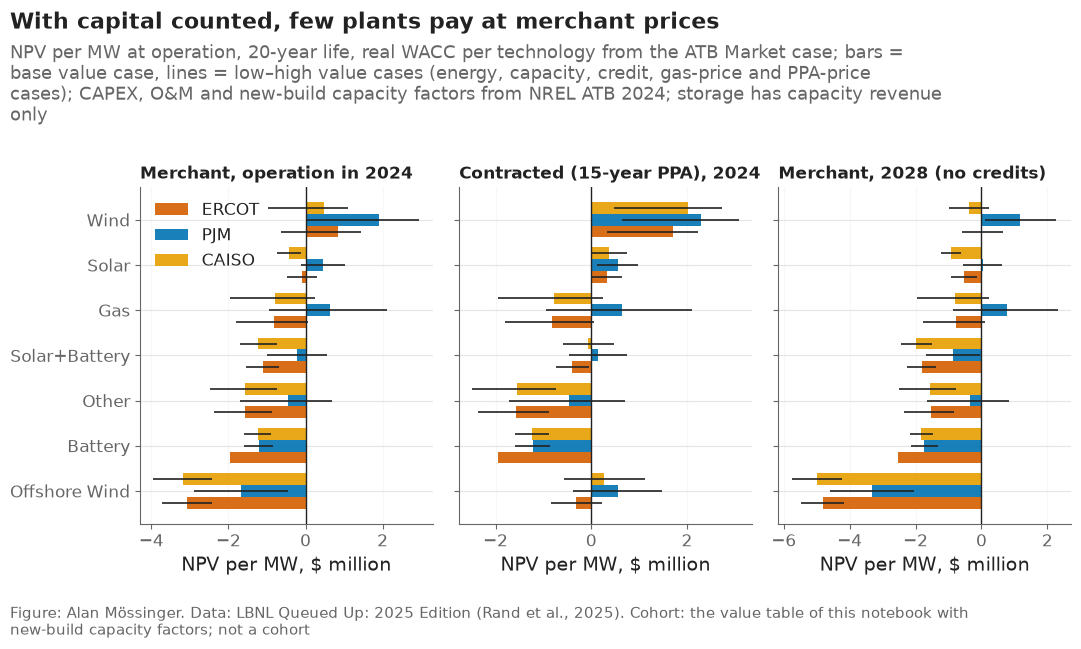

Break-even flat price (merchant NPV = 0 at the ATB WACC) against the price the table captures, $/MWh, operation in 2024:


breakeven_price_base               captured_price_base            
region                       CAISO  ERCOT    PJM               CAISO ERCOT   PJM
tech                                                                            
Battery                        NaN    NaN    NaN                 NaN   NaN   NaN
Gas                           71.6   71.6   71.6                57.7  37.2  51.8
Offshore Wind                105.4  105.4  105.4                46.3  31.6  43.6
Other                         92.2   92.2   92.2                51.7  33.5  46.6
Solar                         44.1   44.1   44.1                34.7  29.8  39.5
Solar+Battery                 77.5   77.5   77.5                45.1  31.6  43.4
Wind                          41.4   41.4   41.4                66.4  57.3  67.8

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5), sharey=True)
order = ["Offshore Wind", "Battery", "Other", "Solar+Battery", "Gas", "Solar", "Wind"]
width = 0.26
panels = [(2024, "npv_per_mw", "Merchant, operation in 2024"), (2024, "npv_contracted", "Contracted (15-year PPA), 2024"), (2028, "npv_per_mw", "Merchant, 2028 (no credits)")]
for ax, (cod_year, col, title) in zip(axes, panels):
    at = npv_table[npv_table["cod_year"] == cod_year].set_index(["tech", "region"])
    y = np.arange(len(order))
    for k, region in enumerate(["ERCOT", "PJM", "CAISO"]):
        part = at.xs(region, level="region").reindex(order)
        yy = y + (k - 1) * width
        ax.barh(yy, part[f"{col}_base"] / 1e6, height=width, color=plots.region_color(region), alpha=0.9, label=region)
        ax.hlines(yy, part[f"{col}_low"] / 1e6, part[f"{col}_high"] / 1e6, color=plots.INK, lw=1.2)
    ax.axvline(0, color=plots.INK, lw=1)
    ax.set_yticks(y); ax.set_yticklabels(order)
    ax.set_title(title, fontsize=12, loc="left")
    ax.set_xlabel("NPV per MW, \\$ million")
    ax.grid(axis="x", alpha=0.3)
axes[0].legend(loc="upper left", frameon=False)
pos = {}
for label, col, cod in [("merchant_2024", "npv_per_mw_base", 2024), ("contracted_2024", "npv_contracted_base", 2024), ("merchant_2028", "npv_per_mw_base", 2028)]:
    pos[label] = int((npv_table[npv_table["cod_year"] == cod][col] > 0).sum())
plots.finish(fig,
             f"With capital counted at the ATB cost of capital, {pos['merchant_2024']} of 21 technology-region pairs pay at merchant prices with today's credits and "
             f"{pos['contracted_2024']} with a 15-year contract at index prices; after the 2027 deadline {pos['merchant_2028']} pay at merchant prices",
             "NPV per MW at operation, 20-year life, real WACC per technology from the ATB Market case; bars = base value case, lines = low–high value cases "
             "(energy, capacity, credit, gas-price and PPA-price cases); CAPEX, O&M and new-build capacity factors from NREL ATB 2024; storage has capacity revenue only",
             "the value table of this notebook with new-build capacity factors; not a cohort")
plots.save_fig(fig, "F26_npv_per_mw", "Net present value per MW at operation by technology and region: merchant revenue with today's credits (2024), a 15-year contract at index prices (2024), and merchant revenue after the credit deadline (2028); 20-year life, ATB real cost of capital per technology, low and high value cases as lines.", NOTEBOOK)
plt.show()
be = npv_table[npv_table["cod_year"] == 2024].pivot(index="tech", columns="region", values=["breakeven_price_base", "captured_price_base"]).round(1)
print("Break-even flat price (merchant NPV = 0 at the ATB WACC) against the price the table captures, $/MWh, operation in 2024:")
be

**Reading this.** Discounted at the technology's own cost of capital, the value index of section 4 turns into two short lists. **Merchant**, for a plant entering operation in 2024 with today's credits: five of the 21 technology-region pairs have a positive base-case NPV per MW, wind in PJM ($1.92 million per MW), ERCOT ($0.83M) and CAISO ($0.49M), gas in PJM ($0.64M) and solar in PJM ($0.45M); solar in ERCOT (−$0.09M) and CAISO (−$0.44M), hybrids, storage and offshore wind are negative. **Contracted**, with a 15-year PPA at index prices: ten pairs are positive, wind everywhere ($1.7–2.3M), solar everywhere ($0.32–0.55M), gas in PJM, offshore wind in PJM and CAISO, hybrids in PJM; storage stays negative because the table gives it capacity revenue only. After the 2027 credit deadline the merchant list shrinks to four (PJM wind, gas and solar, ERCOT wind at $0.03M). The ranges are wide: PJM gas runs from negative to above $2M with the capacity and gas-price cases.

The break-even flat price says the same in the unit a company negotiates in. At the ATB cost of capital a new solar plant needs $44/MWh over twenty years, wind $41, a combined cycle $72 at $3.50 gas, a hybrid $78; the on-peak price the table captures for solar is $30–40/MWh and for wind $57–68. Wind clears its break-even on merchant prices in two regions and solar does not anywhere; a contract at the index level ($57 solar, $62 wind) clears both with room. That gap, not the technology, is what decides the sign of solar, and it is why the gates of notebook 16 are run in both cases. At a flat 8% the break-evens were $57, $51 and $80, and solar was negative in every region: the cost of capital matters as much as the price.

### 8.1 Every test request valued at its decision date

For the gates of notebook 16 each request needs one number: its expected NPV at the day of the decision, `Σ_j P(operates in year j) × NPV_per_MW(COD = entry + j) × MW / (1 + r)^j`, with the level-repaired incidence curve of section 6 (and the raw curve beside it), its own state's capacity factor, and the three value cases. This is the value index of section 6 with capital cost, operating cost, discounting and a 20-year life put in.

In [12]:
npv_records = []
for i, (idx_, r) in enumerate(test.iterrows()):
    rec = {"project_key": str(r["project_key"]), "region": r["region"], "state": r["state"], "tech": r["tech"], "mw": r["mw"], "q_year": int(r["q_year"])}
    rate = WACC[r["tech"]]
    discount = (1 + rate) ** np.arange(1, WINDOW + 1)
    for revenue_case in REVENUE_CASES:
        tag = "" if revenue_case == "merchant" else "contracted_"
        for case in CASES:
            per_mw = np.array([npv_parts(r["region"], r["tech"], int(r["q_year"]) + j, case, rate, revenue_case)[0] for j in range(1, WINDOW + 1)])
            for version, P in [("raw", P_raw), ("recalibrated", P_recal)]:
                increments = np.diff(np.concatenate([[0.0], P[i]]))
                rec[f"expected_npv_{tag}{version}_{case}"] = float((increments * per_mw / discount).sum() * r["mw"])
            rec[f"npv_per_mw_{tag}if_built_year3_{case}"] = float(per_mw[2])
    npv_records.append(rec)
npv_by_request = pd.DataFrame(npv_records)
npv_by_request.to_csv(paths.RESULTS / "npv_by_request.csv", index=False)
for tag, label in [("", "merchant"), ("contracted_", "contracted")]:
    positive = npv_by_request[f"npv_per_mw_{tag}if_built_year3_base"] > 0
    print(f"{label}: share of test requests whose plant would have a positive base-case NPV if built three years after entry: {positive.mean():.1%} "
          f"(by region: {npv_by_request.groupby('region')[f'npv_per_mw_{tag}if_built_year3_base'].apply(lambda s: (s > 0).mean()).round(2).to_dict()})")
print("expected NPV at entry (probability-weighted, discounted), level repaired, base case, $ million — merchant and contracted:")
(npv_by_request[["expected_npv_recalibrated_base", "expected_npv_contracted_recalibrated_base"]] / 1e6).describe().round(2)

merchant: share of test requests whose plant would have a positive base-case NPV if built three years after entry: 57.1% (by region: {'CAISO': 0.07, 'ERCOT': 0.22, 'PJM': 0.8})
contracted: share of test requests whose plant would have a positive base-case NPV if built three years after entry: 76.3% (by region: {'CAISO': 0.22, 'ERCOT': 0.79, 'PJM': 0.87})
expected NPV at entry (probability-weighted, discounted), level repaired, base case, $ million — merchant and contracted:


,expected_npv_recalibrated_base,expected_npv_contracted_recalibrated_base
count,2268.00,2268.00
mean,-2.30,7.15
std,29.03,29.14
min,-325.69,-249.42
25%,-5.26,-0.03
50%,0.33,2.29
75%,4.41,9.82
max,168.22,363.16


**Reading this.** Probability-weighted and discounted to the day of the request at the technology's cost of capital, the median test request has an expected NPV of +$0.3 million in the merchant case and +$2.3 million under contract. If built three years after entry, 80% of PJM's requests, 22% of ERCOT's and 7% of CAISO's would have a positive merchant NPV per MW; under contract 87%, 79% and 22%. The difference is ERCOT's solar, which pays only with a contract, and CAISO's storage and hybrids, which do not pay in either case on the revenue the public files record. These are the quantities the entry gate of notebook 16 tests against the cost of the next study and deposit; the same arithmetic two years in, with the landmark probabilities, is the review gate. Dollar years differ between the ATB costs (2022) and the value table (each year's prices), a gap of a few percent that does not change any sign above.

## 9. Checks

In [13]:
checks = pd.DataFrame([
    {"check": "every value input has a source or an assumption row", "value": len(assumptions), "pass": len(assumptions) >= 10},
    {"check": "capacity revenue parsed for 20 years", "value": len(rpm), "pass": len(rpm) == 20},
    {"check": "ELCC ratings parsed for 18 classes", "value": len(elcc), "pass": len(elcc) == 18},
    {"check": "no missing value in the value table", "value": int(value_table[CASES].isna().sum().sum()), "pass": not value_table[CASES].isna().any().any()},
    {"check": "every test request valued", "value": len(valued), "pass": len(valued) == len(test)},
    {"check": "ATB costs read for every technology group", "value": len(atb), "pass": len(atb) == len(TECHS) and atb["capex_per_kw"].notna().all()},
    {"check": "NPV table complete (3 regions × 7 technologies × 13 COD years, merchant and contracted, 3 cases)", "value": len(npv_table), "pass": len(npv_table) == 3 * 7 * 13 and npv_table.filter(like="npv_").notna().all().all()},
    {"check": "every test request has an expected NPV", "value": len(npv_by_request), "pass": len(npv_by_request) == len(test) and npv_by_request.filter(like="expected_npv").notna().all().all()},
    {"check": "F26 saved as PNG and SVG", "value": 2, "pass": (paths.FIGURES / "F26_npv_per_mw.png").exists() and (paths.FIGURES / "F26_npv_per_mw.svg").exists()},
    {"check": "F13 saved as PNG and SVG", "value": 2,
     "pass": (paths.FIGURES / "F13_expected_mw_and_value.png").exists() and (paths.FIGURES / "F13_expected_mw_and_value.svg").exists()},
])
checks.to_csv(paths.RESULTS / "value_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 0.3 min


,check,value,pass
0,every value input has a source or an assumptio...,24,True
1,capacity revenue parsed for 20 years,20,True
2,ELCC ratings parsed for 18 classes,18,True
3,no missing value in the value table,0,True
4,every test request valued,2268,True
5,ATB costs read for every technology group,7,True
6,NPV table complete (3 regions × 7 technologies...,273,True
7,every test request has an expected NPV,2268,True
8,F26 saved as PNG and SVG,2,True
9,F13 saved as PNG and SVG,2,True


## Takeaways — Part A

- Every value input is parsed from a public file (EIA hub prices, PJM capacity revenue and ELCC ratings, EIA generation and capacity, LBNL PJM costs) or stated with a range and a source in `results/value_assumptions.csv`; the index has no discounting or financing and says so.
- A MW online in 2024 is worth, in the base case, about $249,000 a year for gas in PJM, $135,000 for wind and $62,000 for solar; CAISO's capacity price and the ERCOT price after 2019 are assumptions to verify.
- Interconnection cost exposure peaks at $82/kW for 20–100 MW requests (PJM median); the sunk cost to the next gate is small except for the smallest requests.
- The 2017–2019 cohort: 29.2 GW expected online within five years (raw), 25.2 GW after the level repair, 18.8 GW realised — the level error in megawatts.
- The order of requests by expected value is almost insensitive to the value case (Spearman ≥ 0.97); the probabilities drive the book, the assumptions drive its worth.
- **What goes to the report:** F13; the value and cost tables with their assumption list; the MW-online gap as the portfolio-scale statement of the calibration problem.
- **With capital counted (section 8, F26):** at the ATB cost of capital per technology, five of 21 technology-region pairs pay at merchant prices with today's credits (wind everywhere, gas and solar in PJM) and ten under a 15-year contract at index prices (wind and solar everywhere, PJM gas and hybrids, offshore in PJM and CAISO); four after the 2027 deadline. Break-even flat prices are $44/MWh for solar, $41 for wind and $72 for gas against captured prices of $30–68. The median test request's expected NPV at entry is +$0.3 million merchant and +$2.3 million contracted. Both cases feed the gates of notebook 16; F26 and the break-even table go to the report's "what a project is worth" section.

# Part B — The candidates: a pool across every region, forty in the default book, every number with its provenance (new, 2026-10-12)

The capital decision of PLAN.md §14 chooses among documented opportunities: Gulf of Mexico lease redevelopments valued against their own Arps baseline under the confirmed cost grid (decision #68), and power candidates anchored to real interconnection requests whose chance of operating, and when, comes from the queue models of notebook 04. The pool is every eligible lease and every request of the 2017–2019 test cohort in every region (PLAN.md §14 addendum: all data, one process); the default book is twenty leases and twenty ERCOT requests (five gas, five solar, five wind, five storage), chosen by transparent rules, and the dashboard can widen it. A data-completeness score says how much of each candidate's economics rests on observed hourly prices and plant histories; where it is thin, notebook 08 widens the uncertainty and notebook 09 tightens the constraints.

## Setup

In [14]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, economics as ec, paths, plots, value

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "07_economics"
START = time.time()
R = paths.RESULTS
CASES = list(ec.CASES)
POWER_TECHS = {"Gas": "Gas CC", "Solar": "Solar", "Wind": "Wind", "Battery": "Storage"}  # LBNL type -> candidate technology
DEFAULT_PER_TECH, DEFAULT_LEASES = 5, 20
HORIZON_YEARS = 7  # years after entry over which a request may start operating
LIFE = 20  # operating years valued (as in part A)


def save(fig, name, caption):
    """Save a figure of this notebook under figures/07_economics/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"


lease = pd.read_parquet(paths.DATA_INTERIM / "upstream_monthly.parquet")
market = pd.read_parquet(paths.DATA_INTERIM / "market_monthly.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
pred_landmark = pd.read_parquet(paths.DATA_PROCESSED / "predictions_landmark.parquet")
pred_v2 = pd.read_parquet(paths.DATA_PROCESSED / "predictions_v2.parquet")
atb = pd.read_csv(R / "atb_costs.csv").set_index("tech")
cost_table = pd.read_csv(R / "cost_table.csv").set_index("size_regime")
npv_request = pd.read_csv(R / "npv_by_request.csv").set_index("project_key")
assumptions = pd.read_csv(R / "value_assumptions.csv")
dam = pd.read_parquet(paths.RAW_ERCOT / "ercot_dam_spp_2024.parquet")
hub = dam[dam["Location"] == config.ERCOT_PRICE_HUB].set_index("Interval Start")["SPP"]
wind_solar = pd.read_parquet(paths.RAW_ERCOT / "ercot_wind_solar_2024.parquet")
m24 = market[market["month"].dt.year == 2024]
WTI_2024, HH_2024, ERCOT_2024 = (float(m24[c].mean()) for c in ["wti_usd_bbl_real2024", "hh_usd_mmbtu_real2024", "ercot_usd_mwh_real2024"])
PPA = {"Solar": 57.0, "Wind": 62.0}  # $/MWh, the index-level assumption of part A (value_assumptions.csv, decision #61)
print(f"2024 real prices used as the flat base path: WTI ${WTI_2024:.1f}/bbl, Henry Hub ${HH_2024:.2f}/MMBtu, ERCOT North ${ERCOT_2024:.1f}/MWh (observed 2024 months)")


2024 real prices used as the flat base path: WTI $76.6/bbl, Henry Hub $2.19/MMBtu, ERCOT North $27.0/MWh (observed 2024 months)


## B.1 The lease pool and the twenty redevelopments

Every lease with sixty or more producing months is in the pool; the default book is the twenty with the most 2024 output in barrels of oil equivalent. Each lease carries its redevelopment case from notebook 02 part C — young oil (oil share ≥ 50%, water cut < 50%), mature oil watering out (oil share ≥ 50%, water cut ≥ 50%), gas tail (oil share < 50%) — the number of producing completions worked over, and its Arps baseline from the last 36 observed months.

In [15]:
prod = lease[lease["producing"]]
producing_months = prod.groupby("lease_number").size()
eligible = producing_months[producing_months >= config.V5_MIN_PRODUCING_MONTHS].index
pool_l = (prod[prod["lease_number"].isin(eligible)].groupby("lease_number")
          .agg(oil_bbl_total=("oil_bbl", "sum"), gas_mcf_total=("gas_mcf", "sum"), water_bbl_total=("water_bbl", "sum"),
               producing_months=("month", "size"), first_month=("month", "min"), last_month=("month", "max"),
               operator=("operator_name", lambda s: s.mode().iloc[0]), area_block=("area_block", lambda s: s.mode().iloc[0])))
y24 = prod[prod["month"].dt.year == 2024].groupby("lease_number").agg(oil_2024=("oil_bbl", "sum"), gas_2024=("gas_mcf", "sum"), wells_2024=("n_producing", "max"))
pool_l = pool_l.join(y24, how="left").fillna({"oil_2024": 0.0, "gas_2024": 0.0, "wells_2024": 0})
pool_l["boe_2024"] = pool_l["oil_2024"] + pool_l["gas_2024"] * ec.BOE_PER_MCF
pool_l["oil_share"] = pool_l["oil_bbl_total"] / (pool_l["oil_bbl_total"] + pool_l["gas_mcf_total"] * ec.BOE_PER_MCF)
pool_l["water_cut"] = pool_l["water_bbl_total"] / (pool_l["water_bbl_total"] + pool_l["oil_bbl_total"]).replace(0, np.nan)
pool_l["case"] = np.select([(pool_l["oil_share"] >= 0.5) & (pool_l["water_cut"] < 0.5), pool_l["oil_share"] >= 0.5], ["young oil", "mature oil watering out"], "gas tail")
pool_l["area"] = pool_l["area_block"].str.extract(r"^([A-Z]+)")[0]
pool_l = pool_l[pool_l["last_month"] >= "2024-01-01"].copy()  # a lease that stopped reporting before 2024 has nothing to redevelop
pool_l["n_wells"] = pool_l["wells_2024"].clip(lower=1).astype(int)
pool_l = pool_l.sort_values("boe_2024", ascending=False)
pool_l["in_default_book"] = False
pool_l.iloc[:DEFAULT_LEASES, pool_l.columns.get_loc("in_default_book")] = True
print(f"{len(pool_l):,} leases in the pool (producing in 2024, 60+ producing months); default book: the {DEFAULT_LEASES} largest by 2024 boe, "
      f"{pool_l[pool_l['in_default_book']]['boe_2024'].sum() / 1e6:.0f} million boe in 2024 ({pct(pool_l[pool_l['in_default_book']]['boe_2024'].sum() / pool_l['boe_2024'].sum(), 0)} of the pool); "
      f"cases in the book: {pool_l[pool_l['in_default_book']]['case'].value_counts().to_dict()}")
pool_l[pool_l["in_default_book"]][["operator", "area", "case", "boe_2024", "n_wells", "oil_share", "water_cut"]].round(2).head(10)


513 leases in the pool (producing in 2024, 60+ producing months); default book: the 20 largest by 2024 boe, 306 million boe in 2024 (47% of the pool); cases in the book: {'young oil': 20}


,operator,area,case,boe_2024,n_wells,oil_share,water_cut
lease_number,,,,,,,
G14658,BP EXPLORATION & PRODUCTION INC,MC,young oil,39725007.67,12,0.90,0.36
G15607,BP EXPLORATION & PRODUCTION INC,GC,young oil,26024919.17,24,0.90,0.18
G20082,CHEVRON USA INC,GC,young oil,25989770.67,13,0.90,0.12
G26253,SHELL OFFSHORE INC.,MC,young oil,24739650.33,7,0.91,0.02
G09982,BP EXPLORATION & PRODUCTION INC,GC,young oil,23637206.67,7,0.96,0.35
G21245,UNION OIL COMPANY OF CALIFORNIA,WR,young oil,16899925.83,9,0.96,0.02
G07957,SHELL OFFSHORE INC.,MC,young oil,15945958.83,5,0.84,0.23
G07963,SHELL OFFSHORE INC.,MC,young oil,15329369.17,14,0.85,0.12
G17565,SHELL OFFSHORE INC.,AC,young oil,13784327.33,13,0.79,0.15


## B.2 Lease economics under the grid: incremental NPV, break-even, the three cases

For every lease in the pool: the Arps baseline for 240 months, the redevelopment uplift after the 24-month lead time, the incremental cash flow against doing nothing, discounted at the ATB offshore rate, under the low-cost, base and high-cost settings of the grid; the flat WTI at which the incremental NPV is zero. Prices are the 2024 real means held flat (the scenario engine of notebook 08 replaces them with joint paths). Every cost here is ASSUMED, the production FORECAST, the NPV DERIVED.

In [16]:
ec.UPSTREAM_GRID.to_csv(R / "upstream_cost_grid.csv", index=False)
months = 240
wti_path, hh_path = np.full(months, WTI_2024), np.full(months, HH_2024)
rows = []
oil_w = lease.pivot(index="lease_number", columns="month", values="oil_bbl").fillna(0)
gas_w = lease.pivot(index="lease_number", columns="month", values="gas_mcf").fillna(0)
t0 = time.time()
for lid, r in pool_l.iterrows():
    hist_o, hist_g = oil_w.loc[lid].to_numpy(), gas_w.loc[lid].to_numpy()
    base_o, base_g, fit_o, fit_g = ec.lease_baseline(hist_o, hist_g, months=months)
    row = {"lease_number": lid, "arps_b_oil": fit_o["b"], "arps_d_oil": fit_o["d_i"], "baseline_boe_year1": float((base_o[:12] + base_g[:12] * ec.BOE_PER_MCF).sum())}
    for case in CASES:
        row[f"incremental_npv_{case}"] = ec.incremental_npv(base_o, base_g, wti_path, hh_path, int(r["n_wells"]), case)
    row["capex_base"] = ec.grid_case("base")["workover_cost_per_well_usd"] * int(r["n_wells"])
    row["breakeven_wti_base"] = ec.breakeven_wti(base_o, base_g, hh_path, int(r["n_wells"]), "base")
    rows.append(row)
lease_npv = pd.DataFrame(rows).set_index("lease_number")
pool_l = pool_l.join(lease_npv)
print(f"{len(lease_npv):,} leases valued in {time.time() - t0:.0f} s; default book: incremental NPV base ${pool_l[pool_l['in_default_book']]['incremental_npv_base'].sum() / 1e9:.1f}B "
      f"(low-cost ${pool_l[pool_l['in_default_book']]['incremental_npv_low'].sum() / 1e9:.1f}B, high-cost ${pool_l[pool_l['in_default_book']]['incremental_npv_high'].sum() / 1e9:.1f}B); "
      f"positive at base in the pool: {pct((pool_l['incremental_npv_base'] > 0).mean(), 0)}; median break-even WTI ${pool_l['breakeven_wti_base'].median():.0f}/bbl")
pool_l[pool_l["in_default_book"]][["case", "n_wells", "incremental_npv_low", "incremental_npv_base", "incremental_npv_high", "breakeven_wti_base"]].round(0).head(10)


C:\Users\alanm\OneDrive\Área de Trabalho\CAPSTONE\src\decline.py:79: OptimizeWarning: Covariance of the parameters could not be estimated
  params, _ = curve_fit(log_arps, t_k, log_q, p0=[q0, 0.05, 0.5],


513 leases valued in 6 s; default book: incremental NPV base $14.6B (low-cost $10.0B, high-cost $9.6B); positive at base in the pool: 23%; median break-even WTI $57/bbl


,case,n_wells,incremental_npv_low,incremental_npv_base,incremental_npv_high,breakeven_wti_base
lease_number,,,,,,
G14658,young oil,12,1.753471e+09,2.606570e+09,1.870240e+09,30.0
G15607,young oil,24,1.235217e+09,1.798726e+09,1.136768e+09,33.0
G20082,young oil,13,4.355103e+08,6.081473e+08,3.370922e+08,37.0
G26253,young oil,7,9.484690e+08,1.408699e+09,1.025697e+09,30.0
G09982,young oil,7,3.650170e+08,5.416404e+08,3.653541e+08,32.0
G21245,young oil,9,2.871093e+08,4.193512e+08,2.796314e+08,35.0
G07957,young oil,5,7.322031e+08,1.077279e+09,7.470839e+08,31.0
G07963,young oil,14,5.815391e+08,8.283532e+08,4.794702e+08,35.0
G17565,young oil,13,5.139339e+08,7.332609e+08,4.153468e+08,35.0


**Reading this.** The incremental NPV of a redevelopment is the uplift's cash flow net of the workover and the extra operating cost; it scales with the lease's current rate, so the largest deepwater leases dominate the book, which is also where a cost grid built for the whole Gulf is least precise. The break-even WTI says how much price room each redevelopment has; the gas-tail cases break even on Henry Hub, not on WTI, and show it with high break-evens. None of these numbers is a company's: they are the grid's, and the tornado below says how far each assumption moves the book.

## B.3 The power candidates: ATB costs, 2024 capture, the battery dispatch, and the timing engine

Every request of the 2017–2019 test cohort is in the pool with the expected NPV part A already gives it (the regional value table, merchant and contracted). The ERCOT requests of the four candidate technologies, 20 MW and more, get the v5 economics on top: revenue from the 2024 hourly prices at the North hub — generation-weighted capture for solar and wind from the ERCOT system shapes, economic dispatch for gas combined cycle, one-cycle-a-day energy arbitrage for a four-hour battery (`economics.battery_day`, energy only, no ancillary services) — with ATB costs and the technology's real cost of capital; the chance of operating by each year from the entry model (years 1–3 at the entry landmark, 5 and 7 from the entry predictions), and the cost to carry a request from the cost table. The default book is the five largest requests of each technology.

In [17]:
gas_mc = atb.loc["Gas", "heat_rate_mmbtu_per_mwh"] * HH_2024 + atb.loc["Gas", "vom_per_mwh"]
capture = ec.capture_factors(hub, wind_solar["solar_mw"], wind_solar["wind_mw"], gas_marginal_cost=gas_mc)
battery_rev = ec.battery_annual_revenue(hub, hours=4, efficiency=0.85, cycles=1.0)  # $ per MW-year, 2024 nominal ≈ 2024 real
capture_table = pd.DataFrame([
    {"technology": "Solar", "capture_factor": capture["solar"], "basis": "ERCOT system solar shape × DAM North hub, 2024", "provenance": "DERIVED"},
    {"technology": "Wind", "capture_factor": capture["wind"], "basis": "ERCOT system wind shape × DAM North hub, 2024", "provenance": "DERIVED"},
    {"technology": "Gas CC", "capture_factor": capture["gas"], "basis": f"hours with price above ${gas_mc:.0f}/MWh (heat rate × Henry Hub + VOM): {pct(capture['gas_hours_share'], 0)} of 2024", "provenance": "DERIVED"},
    {"technology": "Storage", "capture_factor": np.nan, "basis": f"one-cycle 4-hour arbitrage on DAM North hub 2024: ${battery_rev / 1e3:.1f}k per MW-year, energy only", "provenance": "DERIVED"},
])
capture_table.to_csv(R / "candidate_capture_factors.csv", index=False)
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
test["operated_by_2024"] = (test["event"] == 1)
test["operation_year_after_entry"] = np.where(test["event"] == 1, np.ceil(test["duration_years"]), np.nan)
lm0 = pred_landmark[(pred_landmark["landmark"].astype(str) == "0")].pivot(index="project_key", columns="horizon_after", values="entry model")
v2 = pred_v2[pred_v2["horizon"].isin([5, 7])].pivot(index="project_key", columns="horizon", values="chosen")


def p_curve(key):
    """Cumulative P(operation by year 1 … 7) at entry (the helper shared with notebook 08)."""
    return ec.operation_curve(key, lm0, v2, years=HORIZON_YEARS)


def revenue_per_mw_year(tech, case="merchant"):
    """$/MW-year and MWh/MW-year of a new plant of ``tech`` on the 2024 ERCOT basis."""
    a = atb.loc[tech]
    if tech == "Battery":
        return battery_rev, 0.0
    cf = capture["gas_hours_share"] if tech == "Gas" else a["new_build_cf"]
    mwh = cf * 8760
    price = ERCOT_2024 * {"Gas": capture["gas"], "Solar": capture["solar"], "Wind": capture["wind"]}[tech]
    if case == "contracted" and tech in PPA:
        price = PPA[tech]
    return price * mwh, mwh


def npv_if_built(tech, case):
    """NPV per MW at the operation date (part A's engine) with the v5 revenue, fuel and the ATB real rate."""
    a = atb.loc[tech]
    rev_m, mwh = revenue_per_mw_year(tech, "merchant")
    rev_c, _ = revenue_per_mw_year(tech, case)
    revenue = np.array([rev_c if (case == "contracted" and tech in PPA and y <= 15) else rev_m for y in range(1, LIFE + 1)])
    fuel = a["heat_rate_mmbtu_per_mwh"] * HH_2024 if tech == "Gas" else 0.0
    return value.npv_per_mw(revenue, a["capex_per_kw"], a["fom_per_kw_year"], a["vom_per_mwh"] + fuel, mwh, rate=a["wacc_real"], life=LIFE)


power_rows = []
for key, r in test.iterrows():
    tech = r["type_clean"]
    row = {"project_key": r["project_key"], "region": r["region"], "state": r["state"], "technology_lbnl": tech, "mw": r["mw"], "q_year": r["q_year"],
           "operated_by_2024": bool(r["operated_by_2024"]), "operation_year_after_entry": r["operation_year_after_entry"],
           "expected_npv_merchant_partA": npv_request["expected_npv_recalibrated_base"].get(r["project_key"], np.nan) if "expected_npv_recalibrated_base" in npv_request else np.nan}
    curve = p_curve(r["project_key"])
    v5 = (r["region"] == "ERCOT") and (tech in POWER_TECHS) and (r["mw"] >= config.FERC_SIZE_STEP_MW) and curve is not None
    row["technology"] = POWER_TECHS.get(tech, "Other")
    row["v5_economics"] = v5
    row["data_completeness"] = 1.0 if v5 else (0.6 if r["region"] in config.TRACK_A_REGIONS else 0.3)
    if v5:
        band = pd.cut([r["mw"]], bins=config.SIZE_BINS, labels=config.SIZE_LABELS, right=False)[0]
        carry = float(cost_table.loc[str(band), "sunk_per_mw_base"]) * r["mw"]
        a = atb.loc[tech]
        for case in ("merchant", "contracted"):
            per_mw = npv_if_built(tech, case)
            by_year = np.array([per_mw * r["mw"] / (1 + a["wacc_real"]) ** j for j in range(1, HORIZON_YEARS + 1)])
            out = ec.power_npv(curve, by_year, carry, a["wacc_real"], years=HORIZON_YEARS)
            row[f"npv_if_built_year1_{case}"] = by_year[0]
            row[f"expected_npv_{case}"] = out["expected_npv"]
        row["p_operation_7y"] = out["p_operation"]
        row["expected_operation_year"] = out["expected_operation_year"]
        row["carry_cost"] = carry
        row["capex"] = a["capex_per_kw"] * 1000 * r["mw"]
        row["wacc_real"] = a["wacc_real"]
        mwh = revenue_per_mw_year(tech)[1] * r["mw"]
        row["generation_mwh_year"] = mwh
        row["co2_t_year"] = mwh * a["heat_rate_mmbtu_per_mwh"] * 53.06 / 1000 if tech == "Gas" else 0.0  # EPA factor for natural gas, kg CO2 per MMBtu
    power_rows.append(row)
pool_p = pd.DataFrame(power_rows)
pool_p["in_default_book"] = False
for tech in POWER_TECHS:
    idx = pool_p[pool_p["v5_economics"] & (pool_p["technology_lbnl"] == tech)].sort_values("mw", ascending=False).head(DEFAULT_PER_TECH).index
    pool_p.loc[idx, "in_default_book"] = True
book_p = pool_p[pool_p["in_default_book"]]
print(f"{len(pool_p):,} requests in the pool ({int(pool_p['v5_economics'].sum())} ERCOT with v5 economics); default book {len(book_p)} requests, {book_p['mw'].sum():,.0f} MW; "
      f"expected NPV merchant ${book_p['expected_npv_merchant'].sum() / 1e6:,.0f}M, contracted ${book_p['expected_npv_contracted'].sum() / 1e6:,.0f}M; "
      f"P(operation by 7 y) mean {book_p['p_operation_7y'].mean():.2f}; operated by 2024 in fact: {int(book_p['operated_by_2024'].sum())} of {len(book_p)}")
book_p[["project_key", "technology", "mw", "p_operation_7y", "expected_operation_year", "expected_npv_merchant", "expected_npv_contracted", "operated_by_2024"]].round(2)


2,268 requests in the pool (226 ERCOT with v5 economics); default book 20 requests, 8,763 MW; expected NPV merchant $-757M, contracted $-281M; P(operation by 7 y) mean 0.13; operated by 2024 in fact: 2 of 20


,project_key,technology,mw,p_operation_7y,expected_operation_year,expected_npv_merchant,expected_npv_contracted,operated_by_2024
1761,ERCOT|20INR0047,Wind,375.06,0.13,4.84,-38031062.25,24872159.16,False
1830,ERCOT|20INR0223,Gas CC,363.00,0.23,4.68,-36388846.27,-36388846.27,False
1831,ERCOT|20INR0224,Gas CC,484.00,0.15,4.57,-33090174.07,-33090174.07,False
1832,ERCOT|20INR0225,Gas CC,484.00,0.15,4.57,-33090174.07,-33090174.07,False
1835,ERCOT|20INR0231,Gas CC,510.00,0.14,4.64,-31258156.90,-31258156.90,True
1850,ERCOT|20INR0252,Gas CC,363.00,0.22,4.65,-35615381.18,-35615381.18,False
1859,ERCOT|20INR0264,Wind,322.00,0.15,4.59,-38577447.60,25672801.93,False
1936,ERCOT|21INR0264,Wind,451.50,0.09,4.50,-32127135.05,19989638.51,False
1939,ERCOT|21INR0268,Solar,587.76,0.06,4.37,-33646132.56,-8014200.56,False
1949,ERCOT|21INR0282,Solar,1221.64,0.06,4.12,-72526467.74,-17245660.94,False


**Reading this.** A power candidate's expected NPV is the NPV if built, weighted by the year it is likely to start and by the chance it never does, minus the deposits and studies spent either way. That weighting is the queue engine at work: at entry the models give most ERCOT requests a one-in-five to one-in-three chance within seven years, so a plant that is worth building is still, on average, worth a fraction of its built value. The 2024 basis is explicit — solar earns 92% and wind 83% of the flat hub price because they produce when it is low, gas combined cycle earns 135% because it runs when it is high, and the battery earns what one cycle a day of energy arbitrage pays — and the realized outcome column says what in fact happened to each request by 2024, which is what the gym scores against.

## B.4 The candidate table, break-evens, the tornado and each project's impact

`investment_candidates.csv` is the pool (every lease and every request, with the default-book flag and the completeness score); `candidate_npv.csv` the forty of the default book in one layout; `candidate_breakeven.csv` the price each needs; `cost_sensitivity.csv` the book's expected NPV when one assumption at a time moves from low to high; `project_impact.csv` each candidate's share of the book's expected NPV and emissions (its CVaR share is added by notebook 09). Every column's provenance is in `provenance_candidates.csv`.

In [18]:
cand_l = pool_l.reset_index().assign(sector="offshore oil and gas", region="GOM", technology="Lease redevelopment",
                                     project_id=lambda t: "LEASE|" + t["lease_number"], data_completeness=0.8, provenance="FORECAST production; ASSUMED costs; DERIVED NPV")
cand_l = cand_l.rename(columns={"incremental_npv_base": "expected_npv_base", "incremental_npv_low": "expected_npv_low_cost", "incremental_npv_high": "expected_npv_high_cost", "capex_base": "capex"})
cand_l["timing_source"] = "24-month lead time (ASSUMED)"
cand_p = pool_p.assign(sector="ERCOT power", project_id=lambda t: "REQ|" + t["project_key"], timing_source="queue models at entry (notebook 04)",
                       provenance=np.where(pool_p["v5_economics"], "OBSERVED 2024 prices; DERIVED capture and NPV; FORECAST timing", "DERIVED (part A regional value table); FORECAST timing"))
cand_p = cand_p.rename(columns={"expected_npv_merchant": "expected_npv_base"})
columns = ["project_id", "sector", "region", "technology", "case", "mw", "boe_2024", "n_wells", "capex", "expected_npv_low_cost", "expected_npv_base", "expected_npv_high_cost",
           "expected_npv_contracted", "breakeven_wti_base", "p_operation_7y", "expected_operation_year", "operated_by_2024", "co2_t_year", "carry_cost", "wacc_real",
           "generation_mwh_year", "timing_source", "data_completeness", "in_default_book", "provenance"]
candidates = pd.concat([cand_l.reindex(columns=columns), cand_p.reindex(columns=columns)], ignore_index=True)
candidates.to_csv(R / "investment_candidates.csv", index=False)
book = candidates[candidates["in_default_book"]].copy()
# break-even of the power candidates: the flat hub price at which the NPV if built in year 1 is zero (merchant)
def breakeven_price(tech):
    a = atb.loc[tech]
    rev_m, mwh = revenue_per_mw_year(tech)
    if tech == "Battery" or mwh == 0:
        return np.nan
    cap = {"Gas": capture["gas"], "Solar": capture["solar"], "Wind": capture["wind"]}[tech]
    fuel = a["heat_rate_mmbtu_per_mwh"] * HH_2024 if tech == "Gas" else 0.0
    lo, hi = 0.0, 500.0
    for _ in range(40):
        mid = (lo + hi) / 2
        npv = value.npv_per_mw(np.full(LIFE, mid * cap * mwh), a["capex_per_kw"], a["fom_per_kw_year"], a["vom_per_mwh"] + fuel, mwh, rate=a["wacc_real"], life=LIFE)
        lo, hi = (mid, hi) if npv < 0 else (lo, mid)
    return (lo + hi) / 2
be_power = {t: breakeven_price(t) for t in POWER_TECHS}
book["breakeven"] = np.where(book["sector"] == "ERCOT power", book["technology"].map({POWER_TECHS[t]: v for t, v in be_power.items()}), book["breakeven_wti_base"])
book["breakeven_unit"] = np.where(book["sector"] == "ERCOT power", "flat hub price $/MWh (merchant, year-1 build)", "flat WTI $/bbl")
book[["project_id", "sector", "technology", "breakeven", "breakeven_unit"]].to_csv(R / "candidate_breakeven.csv", index=False)
book.to_csv(R / "candidate_npv.csv", index=False)
# the tornado: one assumption at a time, the default book's expected NPV (base otherwise)
base_book = float(book["expected_npv_base"].sum())
tornado = []
book_leases = pool_l[pool_l["in_default_book"]]
for item in ec.UPSTREAM_GRID["item"]:
    if item == "lead_time_months":
        continue
    vals = {}
    for side in ("low", "high"):
        override = {item: float(ec.UPSTREAM_GRID.set_index("item").loc[item, side])}
        total = 0.0
        for lid, r in book_leases.iterrows():
            base_o, base_g, _, _ = ec.lease_baseline(oil_w.loc[lid].to_numpy(), gas_w.loc[lid].to_numpy(), months=months)
            total += ec.incremental_npv(base_o, base_g, wti_path, hh_path, int(r["n_wells"]), "base", override)
        vals[side] = total + float(book[book["sector"] == "ERCOT power"]["expected_npv_base"].sum())
    tornado.append({"assumption": item, "low_value": float(ec.UPSTREAM_GRID.set_index("item").loc[item, "low"]), "high_value": float(ec.UPSTREAM_GRID.set_index("item").loc[item, "high"]),
                    "book_npv_at_low": vals["low"], "book_npv_at_high": vals["high"], "sector": "offshore oil and gas"})
for name, (lo_f, hi_f) in {"flat hub price ±20%": (0.8, 1.2), "capture factors ±10%": (0.9, 1.1)}.items():
    vals = {}
    for side, f in (("low", lo_f), ("high", hi_f)):
        total = 0.0
        for _, r in book_p.iterrows():
            tech = r["technology_lbnl"]; a = atb.loc[tech]
            rev_m, mwh = revenue_per_mw_year(tech)
            fuel = a["heat_rate_mmbtu_per_mwh"] * HH_2024 if tech == "Gas" else 0.0
            per_mw = value.npv_per_mw(np.full(LIFE, rev_m * f), a["capex_per_kw"], a["fom_per_kw_year"], a["vom_per_mwh"] + fuel, mwh, rate=a["wacc_real"], life=LIFE)
            by_year = np.array([per_mw * r["mw"] / (1 + a["wacc_real"]) ** j for j in range(1, HORIZON_YEARS + 1)])
            total += ec.power_npv(p_curve(r["project_key"]), by_year, r["carry_cost"], a["wacc_real"])["expected_npv"]
        vals[side] = total + float(book_leases["incremental_npv_base"].sum())
    tornado.append({"assumption": name, "low_value": lo_f, "high_value": hi_f, "book_npv_at_low": vals["low"], "book_npv_at_high": vals["high"], "sector": "ERCOT power"})
tornado = pd.DataFrame(tornado)
tornado["swing"] = (tornado["book_npv_at_high"] - tornado["book_npv_at_low"]).abs()
tornado["base_book_npv"] = base_book
tornado = tornado.sort_values("swing", ascending=False)
tornado.to_csv(R / "cost_sensitivity.csv", index=False)
impact = book[["project_id", "sector", "technology", "expected_npv_base", "co2_t_year", "capex"]].copy()
impact["share_of_book_npv"] = impact["expected_npv_base"] / base_book
impact["share_of_book_co2"] = impact["co2_t_year"].fillna(0) / impact["co2_t_year"].fillna(0).sum()
impact["share_of_book_capex"] = impact["capex"] / impact["capex"].sum()
impact["cvar_share"] = "notebook 09"
impact.sort_values("share_of_book_npv", ascending=False).to_csv(R / "project_impact.csv", index=False)
provenance = pd.DataFrame([
    ("boe_2024, n_wells, mw", "OBSERVED", "BSEE OGOR-A; LBNL queue file"), ("baseline production (Arps)", "FORECAST", "src/decline.py on the last 36 months"),
    ("workover, uplift, opex, royalty, abandonment, differentials, lead time", "ASSUMED", "decision #68 grid, results/upstream_cost_grid.csv"),
    ("WTI, Henry Hub, ERCOT 2024 real means", "OBSERVED", "notebook 01 market table (ERCOT 2024 observed)"), ("capture factors, battery revenue", "DERIVED", "2024 hourly DAM North hub × ERCOT system shapes; one-cycle LP"),
    ("ATB capex, O&M, heat rate, WACC", "OBSERVED", "NREL ATB 2024 (part A)"), ("PPA prices", "ASSUMED", "value_assumptions.csv (decision #61)"),
    ("P(operation by year), expected operation year", "FORECAST", "notebook 04 entry models"), ("carry cost", "DERIVED", "cost_table.csv by size band (part A)"),
    ("expected NPV, break-even, tornado, impact shares", "DERIVED", "this notebook"), ("operated_by_2024", "OBSERVED", "LBNL file, outcome through 2024-12-31"),
], columns=["columns", "provenance", "source"])
provenance.to_csv(R / "provenance_candidates.csv", index=False)
print(f"book of {len(book)}: expected NPV base ${base_book / 1e9:.2f}B (leases ${book[book['sector'] != 'ERCOT power']['expected_npv_base'].sum() / 1e9:.2f}B, "
      f"power merchant ${book[book['sector'] == 'ERCOT power']['expected_npv_base'].sum() / 1e6:,.0f}M); largest swing: {tornado.iloc[0]['assumption']} "
      f"(${tornado.iloc[0]['book_npv_at_low'] / 1e9:.2f}B to ${tornado.iloc[0]['book_npv_at_high'] / 1e9:.2f}B); power break-evens $/MWh: { {POWER_TECHS[t]: round(v, 0) for t, v in be_power.items() if not np.isnan(v)} }")
tornado.round(0)


book of 40: expected NPV base $13.85B (leases $14.61B, power merchant $-757M); largest swing: uplift_share ($5.86B to $21.84B); power break-evens $/MWh: {'Gas CC': 33.0, 'Solar': 64.0, 'Wind': 50.0}


,assumption,low_value,high_value,book_npv_at_low,book_npv_at_high,sector,swing,base_book_npv
1,uplift_share,0.0,0.0,5.864755e+09,2.184460e+10,offshore oil and gas,1.597984e+10,1.385468e+10
2,opex_usd_per_boe,12.0,28.0,1.660711e+10,9.267283e+09,offshore oil and gas,7.339827e+09,1.385468e+10
7,wacc_real,0.0,0.0,1.385468e+10,1.044101e+10,offshore oil and gas,3.413665e+09,1.385468e+10
0,workover_cost_per_well_usd,4000000.0,15000000.0,1.453868e+10,1.265768e+10,offshore oil and gas,1.881000e+09,1.385468e+10
3,royalty_share,0.0,0.0,1.571907e+10,1.385468e+10,offshore oil and gas,1.864396e+09,1.385468e+10
5,oil_differential_usd_per_bbl,3.0,8.0,1.452029e+10,1.285626e+10,offshore oil and gas,1.664033e+09,1.385468e+10
8,flat hub price ±20%,1.0,1.0,1.361262e+10,1.409673e+10,ERCOT power,4.841096e+08,1.385468e+10
9,capture factors ±10%,1.0,1.0,1.373365e+10,1.397570e+10,ERCOT power,2.420548e+08,1.385468e+10
6,gas_differential_usd_per_mmbtu,0.0,1.0,1.390435e+10,1.378016e+10,offshore oil and gas,1.241880e+08,1.385468e+10
4,abandonment_usd_per_well,1000000.0,8000000.0,1.385468e+10,1.385468e+10,offshore oil and gas,0.000000e+00,1.385468e+10


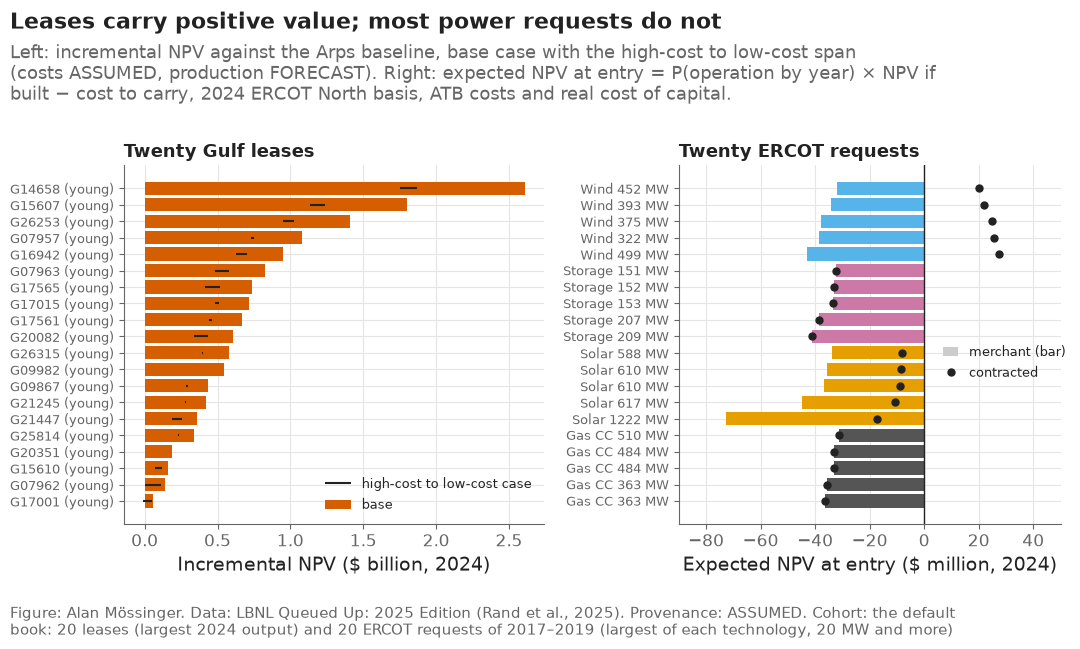

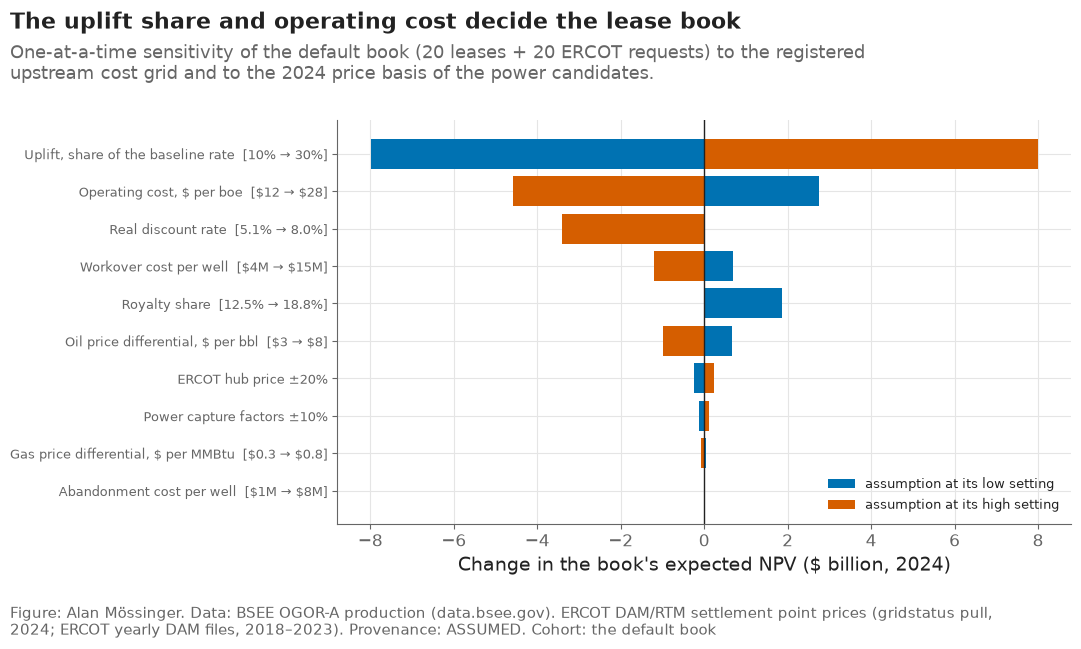

In [19]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
bl = book[book["sector"] != "ERCOT power"].sort_values("expected_npv_base", ascending=True)
y = np.arange(len(bl))
axes[0].barh(y, bl["expected_npv_base"] / 1e9, color="#D55E00", label="base")
axes[0].hlines(y, bl["expected_npv_high_cost"] / 1e9, bl["expected_npv_low_cost"] / 1e9, color=plots.INK, lw=1.5, label="high-cost to low-cost case")
axes[0].set_yticks(y, [f"{r['project_id'].split('|')[1]} ({r['case'].split()[0]})" for _, r in bl.iterrows()], fontsize=9)
axes[0].set_xlabel("Incremental NPV ($ billion, 2024)")
axes[0].legend(loc="lower right", fontsize=9.5)
axes[0].set_title("Twenty Gulf leases", fontsize=13)
bp = book[book["sector"] == "ERCOT power"].sort_values(["technology", "expected_npv_base"], ascending=[True, True])
y = np.arange(len(bp))
colors = bp["technology"].map({"Gas CC": config.TECH_COLORS["Gas"], "Solar": config.TECH_COLORS["Solar"], "Wind": config.TECH_COLORS["Wind"], "Storage": config.TECH_COLORS["Battery"]})
axes[1].barh(y, bp["expected_npv_base"] / 1e6, color=colors)
axes[1].plot(bp["expected_npv_contracted"] / 1e6, y, "o", color=plots.INK, ms=5, label="contracted")
axes[1].axvline(0, color=plots.INK, lw=1)
axes[1].set_yticks(y, [f"{r['technology']} {r['mw']:.0f} MW" for _, r in bp.iterrows()], fontsize=9)
axes[1].set_xlabel("Expected NPV at entry ($ million, 2024)")
axes[1].set_xlim(-90, 50)
axes[1].legend(handles=[Patch(facecolor="#CCCCCC", edgecolor=plots.INK, label="merchant (bar)"), *axes[1].get_legend_handles_labels()[0]],
               loc="center left", bbox_to_anchor=(0.66, 0.45), fontsize=9.5, handlelength=1.2)  # wholly right of zero, beside the storage and solar rows; bars carry the technology colour
axes[1].set_title("Twenty ERCOT requests", fontsize=13)
n_pos_l, n_pos_p = int((bl["expected_npv_base"] > 0).sum()), int((bp["expected_npv_base"] > 0).sum())
plots.finish(fig,
             f"Under the grid, {n_pos_l} of 20 lease redevelopments carry a positive incremental NPV at base; {n_pos_p} of 20 ERCOT requests do at merchant prices once the chance of never operating is priced in",
             "Left: incremental NPV against the Arps baseline, base case with the high-cost to low-cost span (costs ASSUMED, production FORECAST). "
             "Right: expected NPV at entry = P(operation by year) × NPV if built − cost to carry, 2024 ERCOT North basis, ATB costs and real cost of capital.",
             "the default book: 20 leases (largest 2024 output) and 20 ERCOT requests of 2017–2019 (largest of each technology, 20 MW and more)",
             lbnl=True, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="ASSUMED")
plots.save_fig(fig, "F28_candidates", "The forty candidates of the default book: incremental NPV of the lease redevelopments and timing-weighted expected NPV of the ERCOT requests.", NOTEBOOK)
plt.show()
fig, ax = plt.subplots(figsize=(11, 6.5))
t = tornado.iloc[::-1]
y = np.arange(len(t))
ax.barh(y, (t["book_npv_at_low"] - base_book) / 1e9, color="#0072B2", label="assumption at its low setting")
ax.barh(y, (t["book_npv_at_high"] - base_book) / 1e9, color="#D55E00", label="assumption at its high setting")
ax.axvline(0, color=plots.INK, lw=1)
TORNADO_LABELS = {  # grid item -> (label with unit, scale applied to the low and high values, format)
    "uplift_share": ("Uplift, share of the baseline rate", 100, "{:.0f}%"),
    "opex_usd_per_boe": ("Operating cost, $ per boe", 1, "${:.0f}"),
    "wacc_real": ("Real discount rate", 100, "{:.1f}%"),
    "workover_cost_per_well_usd": ("Workover cost per well", 1e-6, "${:.0f}M"),
    "royalty_share": ("Royalty share", 100, "{:.1f}%"),
    "oil_differential_usd_per_bbl": ("Oil price differential, $ per bbl", 1, "${:.0f}"),
    "gas_differential_usd_per_mmbtu": ("Gas price differential, $ per MMBtu", 1, "${:.1f}"),
    "abandonment_usd_per_well": ("Abandonment cost per well", 1e-6, "${:.0f}M"),
}


def tornado_label(name, lo, hi):
    """A readable row label: the item with its unit and its low → high setting; the power multipliers keep their own names."""
    if name not in TORNADO_LABELS:
        return f"{name.replace('flat hub price', 'ERCOT hub price').replace('capture factors', 'Power capture factors')}"
    label, scale, form = TORNADO_LABELS[name]
    return f"{label}  [{form.format(lo * scale)} → {form.format(hi * scale)}]".replace("$", r"\$")  # a bare $ starts matplotlib mathtext


ax.set_yticks(y, [tornado_label(a, lo, hi) for a, lo, hi in zip(t["assumption"], t["low_value"], t["high_value"])], fontsize=9.5)
ax.set_xlabel("Change in the book's expected NPV ($ billion, 2024)")
ax.legend(loc="lower right", fontsize=9.5)
plots.finish(fig,
             f"The book's ${base_book / 1e9:.1f}B expected NPV moves most with {tornado.iloc[0]['assumption']} and {tornado.iloc[1]['assumption']}; every bar is an assumption, not a measurement",
             "One-at-a-time sensitivity of the default book (20 leases + 20 ERCOT requests) to the registered upstream cost grid and to the 2024 price basis of the power candidates.",
             "the default book", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="ASSUMED")
plots.save_fig(fig, "F29_cost_tornado", "One-at-a-time sensitivity of the default book's expected NPV to each cost-grid assumption and to the power price basis.", NOTEBOOK)
plt.show()


**Reading this.** Two pictures the dashboard carries to every viewer. The first says what each candidate is worth and how wide the cost span is around it; the second says which assumption the whole answer leans on — the uplift share and the operating cost for the leases, the price level for the plants. A reader who disagrees with a bar in the tornado can move the slider and watch the book change, which is the point of showing assumptions beside results rather than behind them. The leases dwarf the plants in dollars because they are producing assets with a modest incremental spend, while a power request is a probability of a plant; the optimizer of notebook 09 compares them on risk-adjusted value per dollar of capital, not on size.

## B.5 Checks

In [20]:
checks = pd.DataFrame([
    ("default book: 20 leases and 5 requests per technology", bool(book[book['sector'] != 'ERCOT power'].shape[0] == DEFAULT_LEASES and (book_p.groupby('technology_lbnl').size() == DEFAULT_PER_TECH).all())),
    ("every candidate row has a provenance label and a completeness score", bool(candidates["provenance"].notna().all() and candidates["data_completeness"].between(0, 1).all())),
    ("every grid item is in the exported grid with low, base and high", bool(len(ec.UPSTREAM_GRID) == 9 and ec.UPSTREAM_GRID[["low", "base", "high"]].notna().all().all())),
    ("P(operation) curves are cumulative and within [0, 1]", bool(book_p["p_operation_7y"].between(0, 1).all())),
    ("power break-evens are finite for the generating technologies", bool(all(np.isfinite(v) for t, v in be_power.items() if t != "Battery"))),
    ("tornado rows: the book's NPV at base equals the sum of the candidates", bool(abs(tornado["base_book_npv"].iloc[0] - book["expected_npv_base"].sum()) < 1)),
    ("F28 and F29 saved", (paths.FIGURES / "F28_candidates.png").exists() and (paths.FIGURES / "F29_cost_tornado.png").exists()),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(R / "candidates_checks.csv", index=False)
assert checks["passed"].all(), checks
print(f"part B run time {(time.time() - START) / 60:.1f} min")
checks[["check", "result"]]


part B run time 0.2 min


,check,result
0,default book: 20 leases and 5 requests per tec...,PASS
1,every candidate row has a provenance label and...,PASS
2,every grid item is in the exported grid with l...,PASS
3,P(operation) curves are cumulative and within ...,PASS
4,power break-evens are finite for the generatin...,PASS
5,tornado rows: the book's NPV at base equals th...,PASS
6,F28 and F29 saved,PASS


## Takeaways — Part B

- The pool is every eligible lease and every 2017–2019 request in every region; forty are in the default book by transparent rules, and the dashboard can widen it.
- Lease redevelopments are valued against their own Arps baseline under the confirmed grid; every cost is an assumption with a range, and the tornado says which one the book leans on.
- ERCOT requests carry the queue engine's chance of operating, the 2024 capture factors and the battery's one-cycle revenue; the realized outcome by 2024 sits beside the forecast for the gym.
- **What goes to the report:** F28, F29, `results/investment_candidates.csv`, `results/candidate_npv.csv`, `results/cost_sensitivity.csv`, `results/project_impact.csv`, `results/provenance_candidates.csv`.

## Takeaways

- **Part A** — What a MW online is worth, and what a request costs to carry: its *Takeaways — Part A* cell above says what it found and what goes to the report.
- **Part B** — The candidates: the pool across regions, the forty of the default book, lease economics under the grid, ERCOT power economics on the 2024 basis, the tornado and each project's impact.

**What goes to the report.** Report figures drawn here: F13_expected_mw_and_value, F26_npv_per_mw, F28_candidates, F29_cost_tornado. Every number the report cites from this notebook is read from `results/` by `src/report_numbers.py`.